# Importing Libraries

In [1]:
import hickle
import pandas as pd
import scipy.signal
# import shap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
# from astropy.table import Table
from scipy import ndimage
from tqdm import tqdm
import corner
from PIL import Image
import io

import os

import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

from scipy.stats import chi2
from sklearn.datasets import make_s_curve
import matplotlib as mpl
import matplotlib.pyplot as plt
import tqdm

import ili
from ili.dataloaders import NumpyLoader
from ili.inference import InferenceRunner
from ili.validation.metrics import PosteriorCoverage, PlotSinglePosterior

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

from datasets import load_dataset, DatasetDict
from transformers import ViTFeatureExtractor, ViTForImageClassification, ViTModel, AdamW, AutoImageProcessor, AutoModel
from sklearn.metrics import r2_score
from scipy.stats import spearmanr
from tqdm import tqdm

Device: cuda


/home/juanpabloalfonzo/anaconda3/envs/ili-torch2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:datasets:PyTorch version 2.6.0 available.


Device: cuda


# Importing Data From Saved Models

In [2]:
def check_degeneracy(samples, vb=False):

    covs = np.zeros((samples.shape[1],samples.shape[1]))
    pvals = np.ones((samples.shape[1],samples.shape[1]))
    for i in range(samples.shape[1]):
        for j in range(i):
            covs[i,j], pvals[i,j] = spearmanr(samples[:,i], samples[:,j])

    if vb==True:
        plt.imshow(np.abs(covs[1:,:-1]));
        plt.xticks(np.arange(5), labels[0:5])
        plt.yticks(np.arange(5), labels[1:])
        plt.colorbar(); plt.show()
        
        plt.imshow(np.abs((pvals<0.05)[1:,:-1]))
        plt.xticks(np.arange(5), labels[0:5])
        plt.yticks(np.arange(5), labels[1:])
        plt.colorbar(); plt.show()

    return covs[1:,:-1], pvals[1:,:-1]

In [3]:
GSWLC_data = load_dataset('juanpabloalfonzo/GSWLC_Data',split='train')
gswlc_data = pd.DataFrame(GSWLC_data)

gswlc_images = load_dataset('juanpabloalfonzo/GSWLC_Images',split='train')
gswlc_images = gswlc_images['images'].copy()

In [4]:
#Importing photometry data and smoothing out outliers

temp_fuv = np.array(gswlc_data['FUV']).copy()
temp_fuv[temp_fuv > 25] = 25 + 0.3*np.random.normal(size=(np.sum(temp_fuv>25),))

temp_w2 = np.array(gswlc_data['W2']).copy()
temp_w2[temp_w2 > 23] = 23

temp_w3 = np.array(gswlc_data['W3']).copy()
temp_w3[temp_w3 > 23] = 23 + 0.3*np.random.normal(size=(np.sum(temp_w3>23),))

temp_w4 = np.array(gswlc_data['W4']).copy()
temp_w4[temp_w4 > 23] = 23 + 0.3*np.random.normal(size=(np.sum(temp_w4>23),))

eleven_bands_SED = np.array((temp_fuv, 
               gswlc_data['NUV'],
               gswlc_data['u'],
               gswlc_data['g'],
               gswlc_data['r'],
               gswlc_data['i'],
               gswlc_data['z'],
               gswlc_data['W1'],
               temp_w2,
               temp_w3,
               temp_w4,)).T

tempt50 = np.array(gswlc_data['t_50']).copy()
tempt50[(tempt50 > 13.7)] = 13.7

tempssfr = np.array(gswlc_data['logSSFR_50']).copy()
tempssfr[tempssfr < -3.5] = tempssfr[tempssfr < -3.5] + 0.3*np.random.normal(size=(np.sum(tempssfr < -3.5),))

tempmet = np.array(gswlc_data['logOH_50']).copy()
tempmet[tempmet < 7.1] = tempmet[tempmet < 7.1] + 0.1*np.random.normal(size=(np.sum(tempmet < 7.1),))

#Importing the true values of the galaxy physical properties from SED fitting 

theta = np.vstack((gswlc_data['logM_50_x'], 
                   tempssfr,
                   gswlc_data['specz'],
                   tempt50,
                   gswlc_data['tauV_50'],
                   tempmet)).T
                #    manga_scalars['sersic_n'])).T
theta[np.isnan(theta)] = 0.

five_bands_SED= np.array((
               gswlc_data['u'],
               gswlc_data['g'],
               gswlc_data['r'],
               gswlc_data['i'],
               gswlc_data['z'],
               )).T



In [152]:
#Importing trained ILI models 
posterior_ensemble_sed_5_bands , summaries_sed_5_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_5_bands_SED_train_set.hickle')
posterior_ensemble_sed , summaries_sed = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_11_bands_SED_train_set.hickle')
posterior_ensemble_im, summaries_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_images_train_set.hickle')
posterior_ensemble_combined_5_bands, summaries_combined_5_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_combined_5_bands.hickle')
posterior_ensemble_combined_11_bands, summaries_combined_11_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_combined_11_bands.hickle')
posterior_ensemble_half_size_im, summaries_half_size_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_half_size.hickle')
posterior_ensemble_quarter_size_im, summaries_quarter_size_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_quarter_size.hickle')
posteiror_ensemble_eight_size_im, summaries_eight_size_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_eight_size.hickle')
posterior_ensemble_g_band_im, summaries_g_band_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/clean_trained_ILIs/trained_ILI_g_band_images.hickle')

#Importing ViT embeddings
gswlc_embeds =  hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/ViT_embeds/gswlc_emebds_clean.hickle')
gswlc_embeds_half_size = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/ViT_embeds/gswlc_emebds_half_size_clean.hickle')
gswlc_embeds_quarter_size = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/ViT_embeds/gswlc_emebds_quarter_size_clean.hickle')
gswlc_embeds_eight_size = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/ViT_embeds/gswlc_emebds_eight_size_clean.hickle')
gswlc_embeds_g_band = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/ViT_embeds/gswlc_emebds_g_band_clean.hickle')
train_index = int(0.8*len(gswlc_data))

In [ ]:
# Gathering all the predictions from the ILI models on the test set
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-15,-8),(0,0.15),(0,13.7),(0,3),(-1.5,0.25)]
labels = ['log M$_*$', 'log SFR','redshift','t50','Av','Z']

all_covs_sed, all_samples_sed = [], []
all_covs_im, all_samples_im = [], []

for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_sed = eleven_bands_SED[gid,:]
    xobs_im = gswlc_embeds[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_sed = posterior_ensemble_sed.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
    posterior_samples_sed = posterior_samples_sed.cpu().numpy()
    covs_sed, _ = check_degeneracy(posterior_samples_sed)

    posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
    posterior_samples_im = posterior_samples_im.cpu().numpy()
    covs_im, _ = check_degeneracy(posterior_samples_im)

    all_covs_sed.append(covs_sed)
    all_samples_sed.append(posterior_samples_sed)
    all_covs_im.append(covs_im)
    all_samples_im.append(posterior_samples_im)

all_covs_sed_5_bands, all_samples_sed_5_bands = [], []

for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_sed = five_bands_SED[gid,:]
    # xobs_sed = five_bands_SED[gid,:]
    # xobs_im = infer(Image.open(io.BytesIO(gswlc_images[gid])))
    xobs_im = gswlc_embeds[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_sed_5_bands = posterior_ensemble_sed_5_bands.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
    posterior_samples_sed_5_bands = posterior_samples_sed_5_bands.cpu().numpy()
    covs_sed_5_bands, _ = check_degeneracy(posterior_samples_sed_5_bands)

    all_covs_sed_5_bands.append(covs_sed_5_bands)
    all_samples_sed_5_bands.append(posterior_samples_sed_5_bands)

all_covs_combined_5_bands, all_samples_combined_5_bands = [], []
for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_sed = five_bands_SED[gid,:]
    # xobs_sed = five_bands_SED[gid,:]
    # xobs_im = infer(Image.open(io.BytesIO(gswlc_images[gid])))
    xobs_im = gswlc_embeds[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_combined_5_bands = posterior_ensemble_combined_5_bands.sample((1000,), torch.Tensor(np.hstack((xobs_im,xobs_sed))).to(device), show_progress_bars = False)
    posterior_samples_combined_5_bands = posterior_samples_combined_5_bands.cpu().numpy()
    covs_combined_5_bands, _ = check_degeneracy(posterior_samples_combined_5_bands)

    all_covs_combined_5_bands.append(covs_combined_5_bands)
    all_samples_combined_5_bands.append(posterior_samples_combined_5_bands)

all_covs_combined_11_bands, all_samples_combined_11_bands = [], []
for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_sed = eleven_bands_SED[gid,:]
    # xobs_sed = five_bands_SED[gid,:]
    # xobs_im = infer(Image.open(io.BytesIO(gswlc_images[gid])))
    xobs_im = gswlc_embeds[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_combined_11_bands = posterior_ensemble_combined_11_bands.sample((1000,), torch.Tensor(np.hstack((xobs_im,xobs_sed))).to(device), show_progress_bars = False)
    posterior_samples_combined_11_bands = posterior_samples_combined_11_bands.cpu().numpy()
    covs_combined_11_bands, _ = check_degeneracy(posterior_samples_combined_11_bands)

    all_covs_combined_11_bands.append(covs_combined_11_bands)
    all_samples_combined_11_bands.append(posterior_samples_combined_11_bands)

all_covs_half_size_im, all_samples_half_size_im = [], []
for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_im = gswlc_embeds_half_size[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_half_size_im = posterior_ensemble_half_size_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
    posterior_samples_half_size_im = posterior_samples_half_size_im.cpu().numpy()
    covs_half_size_im, _ = check_degeneracy(posterior_samples_half_size_im)

    all_covs_half_size_im.append(covs_half_size_im)
    all_samples_half_size_im.append(posterior_samples_half_size_im)

all_covs_g_band_im, all_samples_g_band_im = [], []
for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_im = gswlc_embeds_g_band[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_g_band_im = posterior_ensemble_g_band_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
    posterior_samples_g_band_im = posterior_samples_g_band_im.cpu().numpy()
    covs_g_band_im, _ = check_degeneracy(posterior_samples_g_band_im)

    all_covs_g_band_im.append(covs_g_band_im)
    all_samples_g_band_im.append(posterior_samples_g_band_im)


all_covs_quarter_size_im, all_samples_quarter_size_im = [], []
for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_im = gswlc_embeds_quarter_size[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_quarter_size_im = posterior_ensemble_quarter_size_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
    posterior_samples_quarter_size_im = posterior_samples_quarter_size_im.cpu().numpy()
    covs_quarter_size_im, _ = check_degeneracy(posterior_samples_quarter_size_im)

    all_covs_quarter_size_im.append(covs_quarter_size_im)
    all_samples_quarter_size_im.append(posterior_samples_quarter_size_im)

In [153]:
#all covs and samples for eight size images
all_covs_eight_size_im, all_samples_eight_size_im = [], []
for gid in tqdm(range(train_index, len(gswlc_data))):
    xobs_im = gswlc_embeds_eight_size[gid,:]
    x_truth = theta[gid,:]

    posterior_samples_eight_size_im = posteiror_ensemble_eight_size_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
    posterior_samples_eight_size_im = posterior_samples_eight_size_im.cpu().numpy()
    covs_eight_size_im, _ = check_degeneracy(posterior_samples_eight_size_im)

    all_covs_eight_size_im.append(covs_eight_size_im)
    all_samples_eight_size_im.append(posterior_samples_eight_size_im)

hickle.dump((all_covs_eight_size_im, all_samples_eight_size_im),'/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/eight_size_image_samples_and_covs.hickle')

100%|██████████| 46469/46469 [33:20<00:00, 23.23it/s]


In [ ]:
#Loading the saved samples and covariances that are generated from the cell above (it is advised to save the results of the cell above using hickle.dump)

all_covs_sed, all_samples_sed = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/11_bands_SED_samples_and_covs.hickle')
all_covs_im, all_samples_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/images_samples_and_covs.hickle')

cov_array_sed = np.array(all_covs_sed)
cov_array_im = np.array(all_covs_im)
cov_array_sed.shape, cov_array_im.shape

all_covs_sed_5_bands, all_samples_sed_5_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/5_bands_SED_samples_and_covs.hickle')

cov_array_sed_5_bands = np.array(all_covs_sed_5_bands)
cov_array_sed_5_bands.shape

all_covs_combined_5_bands, all_samples_combined_5_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/combined_5_bands_samples_and_covs.hickle')
cov_array_combined_5_bands = np.array(all_covs_combined_5_bands)
cov_array_combined_5_bands.shape

all_covs_combined_11_bands, all_samples_combined_11_bands = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/combined_11_bands_samples_and_covs.hickle')
cov_array_combined_11_bands = np.array(all_covs_combined_11_bands)
cov_array_combined_11_bands.shape

all_covs_half_size_im, all_samples_half_size_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/half_size_image_samples_and_covs.hickle')
cov_array_half_size_im = np.array(all_covs_half_size_im)
cov_array_half_size_im.shape

all_covs_quarter_size_im, all_samples_quarter_size_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/quarter_size_image_samples_and_covs.hickle')
cov_array_quarter_size_im = np.array(all_covs_quarter_size_im)
cov_array_quarter_size_im.shape

all_covs_eight_size_im, all_samples_eight_size_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/eight_size_image_samples_and_covs.hickle')
cov_array_eight_size_im = np.array(all_covs_eight_size_im)
cov_array_eight_size_im.shape

all_covs_g_band_im, all_samples_g_band_im = hickle.load('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/samples_and_covs/g_band_image_samples_and_covs.hickle')
cov_array_g_band_im = np.array(all_covs_g_band_im)
cov_array_g_band_im.shape


train_index = int(0.8*len(gswlc_data))
sample_size = len(gswlc_data) - train_index

In [ ]:
# morph_data = pd.read_csv('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/matched_morph_data_v4.csv')
morph_data = load_dataset('juanpabloalfonzo/GSWLC_morph',split='train')
morph_data = pd.DataFrame(morph_data)

if 'ID' not in gswlc_data.columns:
        print("\nError: 'ID' column not found in gswlc_data.")
elif 'ID' not in morph_data.columns:
    print("\nError: 'ID' column not found in morph_data.")
# Check if 'sersic_n_morph' exists in morph_data
elif 'bt_morph' not in morph_data.columns:
        print("\nError: 'bt_morph' column not found in morph_data.")
else:
    # Optional: Ensure 'ID' columns have the same data type if needed
    # gswlc_data['ID'] = gswlc_data['ID'].astype(int)
    # morph_data['ID'] = morph_data['ID'].astype(int)
    print("\nData loaded successfully. Proceeding with merge...")

    # --- Perform the left merge ---
    # We select only the 'ID' and 'sersic_n_morph' columns from morph_data
    gswlc_data_merged = pd.merge(gswlc_data, morph_data[['ID', 'pbulge_morph','bt_morph','half_light_radius_morph', 'bulge_n_morph', 'disk_n_morph', 'ttype_morph', 'pbar_morph', 'pdisk_morph', 'pedgeon_morph', 'pmerger_morph']], on='ID', how='left')

    # --- Display results ---
    print("\nMerge complete. Updated gswlc_data DataFrame head:")
    print(gswlc_data_merged.head())

    # Check for NaN values in the new column
    print("\nNumber of NaN values in 'bulge_n_morph' after merge:")
    print(gswlc_data_merged['bulge_n_morph'].isnull().sum())

    # You might want to assign the merged result back or use the new DataFrame:
    # gswlc_data = gswlc_data_merged

sersic_n = np.array(gswlc_data_merged['bulge_n_morph'][train_index:])
bt = np.array(gswlc_data_merged['bt_morph'][train_index:])
pbulge = np.array(gswlc_data_merged['pbulge_morph'][train_index:])
ttype= np.array(gswlc_data_merged['ttype_morph'][train_index:])
pbar = np.array(gswlc_data_merged['pbar_morph'][train_index:])
pdisk = np.array(gswlc_data_merged['pdisk_morph'][train_index:])
pedgeon = np.array(gswlc_data_merged['pedgeon_morph'][train_index:])
pmerger = np.array(gswlc_data_merged['pmerger_morph'][train_index:])


In [11]:
#Convinent variables for plotting
mvals = theta[train_index:,0]
sfrvals = theta[train_index:,1] + theta[train_index:,0] - 9

In [182]:
#Calculating the errors and standard deviations of the predictions from the ILI models (image and 5 band photometry)
nqty = 6
allsederr, allimerr, allsedstd, allimstd = [], [], [], []

allimerr_raw = []
allsederr_raw = []
allimpred, allsedpred = [], []

target_sed = all_samples_sed_5_bands

imtrue_error, sedtrue_error = [], []

for gid in range(sample_size):
    
    sed_err, im_err, sed_std, im_std, sed_err_raw, im_err_raw, im_pred, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))

    im_true_error, sed_true_error = np.zeros((nqty,)), np.zeros((nqty,))

    for i in range(nqty):
            
        q1_im = (all_samples_im[gid][:,i] - theta[train_index+gid, i])
        q2_im = (np.nanmedian(all_samples_im[gid][:,i]) - theta[train_index+gid, i])
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        q2_sed = (np.nanmedian(target_sed[gid][:,i]) - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        im_err[i] = np.nanmean(np.sqrt(q1_im**2))
        im_std[i] = np.nanstd(q1_im)
        im_err_raw[i] = np.nanmean(q1_im)
        sed_err_raw[i] = np.nanmean(q1_sed)
        im_pred[i] = np.nanmean(all_samples_im[gid][:,i])
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])

        im_true_error[i]=(q2_im)
        sed_true_error[i]=(q2_sed)
    
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allimerr.append(im_err)
    allimstd.append(im_std)
    allimerr_raw.append(im_err_raw)
    allsederr_raw.append(sed_err_raw)
    allimpred.append(im_pred)
    allsedpred.append(sed_pred)
    imtrue_error.append(im_true_error)
    sedtrue_error.append(sed_true_error)

   
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allimerr = np.array(allimerr)
allimstd = np.array(allimstd)
allsederr_raw = np.array(allsederr_raw)
allimerr_raw = np.array(allimerr_raw)
allsedpred = np.array(allsedpred)
allimpred = np.array(allimpred)

#Rename all the arrays above to 5 bands in their name
allsederr_5_bands = allsederr
allsedstd_5_bands = allsedstd
allimerr_5_bands = allimerr
allimstd_5_bands = allimstd
allsederr_raw_5_bands = allsederr_raw
allimerr_raw_5_bands = allimerr_raw
allsedpred_5_bands = allsedpred
allimpred_5_bands = allimpred

im_true_error = np.array(imtrue_error)
sed_true_error_5_bands = np.array(sedtrue_error)


In [183]:
np.shape(im_true_error), np.shape(sed_true_error_5_bands)

((46469, 6), (46469, 6))

In [187]:
np.nanmedian(im_true_error[:,2]), np.nanmedian(sed_true_error_5_bands[:,2])

(np.float64(0.001642492040634158), np.float64(0.0012201950569152853))

In [13]:
#Calculating the errors and standard deviations of the predictions from the ILI models (11 band photometry)
nqty = 6
allsederr, allsedstd = [], []


allsederr_raw = []
allsedpred = []

target_sed = all_samples_sed

for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)

#Rename all the arrays above to 11 bands in their name
allsederr_11_bands = allsederr
allsedstd_11_bands = allsedstd
allsederr_raw_11_bands = allsederr_raw
allsedpred_11_bands = allsedpred


In [96]:
#Calculating the errors and standard deviations of the predictions from the ILI models (combined 5 band photometry)
nqty = 6
allsederr, allsedstd = [], []


allsederr_raw = []
allsedpred = []

target_sed = all_samples_combined_5_bands

for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)

#Rename all the arrays above to 11 bands in their name
allsederr_combined_5_bands = allsederr
allsedstd_combined_5_bands = allsedstd
allsederr_raw_combined_5_bands = allsederr_raw
allsedpred_combined_5_bands = allsedpred


In [97]:
#Calculating the errors and standard deviations of the predictions from the ILI models (combined 11 band photometry)
nqty = 6
allsederr, allsedstd = [], []


allsederr_raw = []
allsedpred = []

target_sed = all_samples_combined_11_bands

for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)

#Rename all the arrays above to 11 bands in their name
allsederr_combined_11_bands = allsederr
allsedstd_combined_11_bands = allsedstd
allsederr_combined_raw_11_bands = allsederr_raw
allsedpred_combined_11_bands = allsedpred


In [72]:
#Calculating the errors and standard deviations of the predictions from the ILI models (half size images)
nqty = 6
allsederr, allsedstd = [], []


allsederr_raw = []
allsedpred = []

target_sed = all_samples_half_size_im

for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)

#Rename all the arrays above to half size images in their name
allimerr_half_size = allsederr
allimstd_half_size = allsedstd
allimerr_half_size_raw = allsederr_raw
allimpred_half_size = allsedpred

In [143]:
#Calculating the errors and standard deviations of the predictions from the ILI models (quarter size images)
nqty = 6
allsederr, allsedstd = [], []
allsederr_raw = []
allsedpred = []
target_sed = all_samples_quarter_size_im
for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)

allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)
#Rename all the arrays above to quarter size images in their name
allimerr_quarter_size = allsederr
allimstd_quarter_size = allsedstd
allimerr_quarter_size_raw = allsederr_raw
allimpred_quarter_size = allsedpred

In [154]:
#Calculating the errors and standard deviations of the predictions from the ILI models (eight size images)
nqty = 6
allsederr, allsedstd = [], []
allsederr_raw = []
allsedpred = []
target_sed = all_samples_eight_size_im
for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)
#Rename all the arrays above to eight size images in their name
allimerr_eight_size = allsederr
allimstd_eight_size = allsedstd
allimerr_eight_size_raw = allsederr_raw
allimpred_eight_size = allsedpred

In [73]:
#Calculating the errors and standard deviations of the predictions from the ILI models (single band images)
nqty = 6
allsederr, allsedstd = [], []


allsederr_raw = []
allsedpred = []

target_sed = all_samples_g_band_im

for gid in range(sample_size):
    
    sed_err, sed_std, sed_err_raw, sed_pred = np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,)), np.zeros((nqty,))
    
    for i in range(nqty):
        q1_sed = (target_sed[gid][:,i] - theta[train_index+gid, i])
        sed_err[i] = np.nanmean(np.sqrt(q1_sed**2))
        sed_std[i] = np.nanstd(q1_sed)
        sed_err_raw[i] = np.nanmean(q1_sed)
        sed_pred[i] = np.nanmean(target_sed[gid][:,i])
    allsederr.append(sed_err)
    allsedstd.append(sed_std)
    allsederr_raw.append(sed_err_raw)
    allsedpred.append(sed_pred)
    
allsederr = np.array(allsederr)
allsedstd = np.array(allsedstd)
allsederr_raw = np.array(allsederr_raw)
allsedpred = np.array(allsedpred)

#Rename all the arrays above to half size images in their name
allimerr_g_band = allsederr
allimstd_g_band = allsedstd
allimerr_g_band_raw = allsederr_raw
allimpred_g_band = allsedpred

(array([16780., 20474., 24066., 32229., 34006., 25513., 24890., 21961.,
        18627., 13797.]),
 array([0.020001 , 0.0340009, 0.0480008, 0.0620007, 0.0760006, 0.0900005,
        0.1040004, 0.1180003, 0.1320002, 0.1460001, 0.16     ]),
 <BarContainer object of 10 artists>)

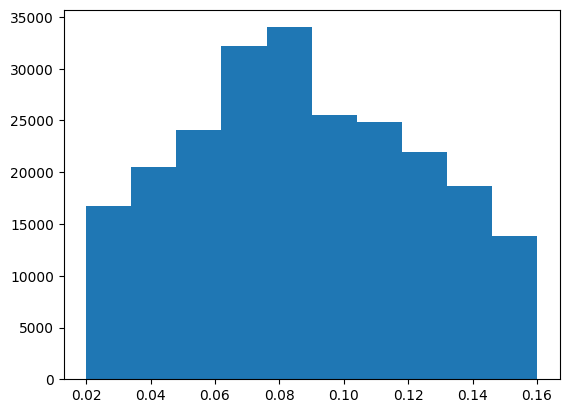

In [164]:
plt.hist(theta[:,2])

(array([9.0000e+00, 7.5000e+01, 8.0900e+02, 4.2690e+03, 1.5334e+04,
        1.9657e+04, 5.4470e+03, 7.8400e+02, 8.0000e+01, 5.0000e+00]),
 array([-0.11170538, -0.08955126, -0.06739713, -0.045243  , -0.02308888,
        -0.00093475,  0.02121937,  0.0433735 ,  0.06552762,  0.08768175,
         0.10983587]),
 <BarContainer object of 10 artists>)

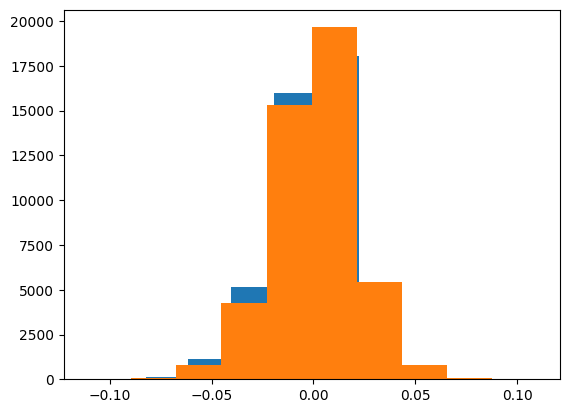

In [205]:
plt.hist(allimerr_raw[:,2])
plt.hist(im_true_error[:,2])

In [197]:
for i in range(6):
    # print(i,np.nanmean(allsederr_combined_5_bands[:,i]))
    print(i,np.nanmedian(allimerr[:,i]))
print('---')

# for i in range(6):
#     print(i,np.nanmedian(sed_true_error_5_bands[:,i]))

# print('---')
#compare to combined 5 bands, 5 bands, and 11 bands


for i in range(6):
    print(i,np.nanmedian(allsederr_5_bands[:,i]))

print('---')
for i in range(6):
    print(i,np.nanmedian(allsederr_combined_5_bands[:,i]))

print('---')
for i in range(6):
    print(i,np.nanmedian(allsederr_11_bands[:,i]))

0 0.23297962123870863
1 0.6203332937971829
2 0.019125374149059175
3 1.0133158199024201
4 0.4814188523113728
5 0.24029193832646858
---
0 0.25095256099700924
1 0.5971828091506888
2 0.02290360970118344
3 1.0206888297080994
4 0.5692431230101733
5 0.27304593799591065
---
0 0.20506640625762906
1 0.4976129744488894
2 0.017505940567038535
3 0.959364096248627
4 0.4305909122439027
5 0.23267894016265905
---
0 0.17216480640411377
1 0.20080948218583314
2 0.016164741514370796
3 0.6226539442481995
4 0.14489407852697372
5 0.10204234039306628


In [155]:
for i in range(6):
    # print(i,np.nanmean(allsederr_combined_5_bands[:,i]))
    print(i,np.nanmedian(allimerr[:,i]))
print('---')

for i in range(6):
    print(i,np.nanmedian(allimerr_g_band[:,i]))

print('---')
for i in range(6):
    print(i,np.nanmedian(allimerr_half_size[:,i]))

print('---')
for i in range(6):
    print(i,np.nanmedian(allimerr_quarter_size[:,i]))

print('---')
for i in range(6):
    print(i,np.nanmedian(allimerr_eight_size[:,i]))

0 0.23297962123870863
1 0.6203332937971829
2 0.019125374149059175
3 1.0133158199024201
4 0.4814188523113728
5 0.24029193832646858
---
0 0.3372463107376101
1 0.744180974495685
2 0.0218241139279654
3 1.1123493082332607
4 0.6167449318536519
5 0.26940389328765846
---
0 0.23855378968811033
1 0.6389082764287747
2 0.020186205039716954
3 1.0307598601932528
4 0.5058459988579825
5 0.24810678899765012
---
0 0.24885098764801059
1 0.6669059826643615
2 0.0212006630301106
3 1.041159920747757
4 0.5239357170178889
5 0.26060725315475486
---
0 0.2923090898590091
1 0.7448935492913056
2 0.024306810633404136
3 1.071521439174652
4 0.5837999521449806
5 0.2737667061195374


In [156]:
for i in range(6):
    print(i,np.nanmedian(allimstd[:,i]))
print('---')
for i in range(6):
    print(i,np.nanmedian(allsedstd_5_bands[:,i]))
print('---')
for i in range(6):
    print(i,np.nanmedian(allsedstd_combined_5_bands[:,i]))
print('---')
for i in range(6):
    print(i,np.nanmedian(allsedstd_11_bands[:,i]))

0 0.22974847283237482
1 0.6235006476343914
2 0.018831104010423587
3 0.9474045681304234
4 0.514743881962146
5 0.2859817764789114
---
0 0.2576409377522086
1 0.6340560747779884
2 0.023305707617294537
3 0.9674523975651808
4 0.6216879637595135
5 0.3180454322413423
---
0 0.2045609763433398
1 0.5296977242637304
2 0.017521028717161415
3 0.9226662237962066
4 0.46181921206531457
5 0.2819764168334119
---
0 0.1786477022640701
1 0.21194328232806678
2 0.016683503325228353
3 0.6044006878263279
4 0.14709985808820228
5 0.10583097955438131


# Figure 2

Image Accuracy

In [ ]:
from sklearn.metrics import r2_score
train_index = int(0.8*len(gswlc_data))
np.random.seed(12)
gal_ids = np.arange(train_index, len(gswlc_data))
ranges = [(9,12),(-15,-8),(0,1.0),(0,13.7),(0,3),(7.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

posteriors = all_samples_im
# posteriors = []
truths = []

for gid in tqdm(gal_ids):
    
    # x = gswlc_embeds
    # x = x_sed
    # xobs = x[gid]
    # posterior_samples = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs).to(device), show_progress_bars=False)
    # posterior_samples = posterior_samples.cpu().numpy()
    # posteriors.append(np.array(posterior_samples))
    truths.append(theta[gid])

truth_array = np.array(truths)
truth_array.shape

for i in range(truth_array.shape[1]):
    plt.figure(figsize=(4,4))
    xax = truth_array[:,i]
    if labels[i] == 'log M$_*$':
        xax[xax > 12] = 12
    # if labels[i] == 'log sSFR':
    #     xax[xax>-7] = -7
    #     xax[xax<-15] = -15
    yax = np.array([np.nanpercentile(posteriors[j][:,i],50) for j in range(len(posteriors))])
    yax_lo = np.array([np.nanpercentile(posteriors[j][:,i],16) for j in range(len(posteriors))])
    yax_hi = np.array([np.nanpercentile(posteriors[j][:,i],84) for j in range(len(posteriors))])
    wts = ((np.nanmax(xax)-np.nanmin(xax))/(yax_hi-yax_lo))**2*1
    rsq = r2_score(xax, yax)
    bias = np.nanmedian(xax-yax)
    var = np.sqrt(np.nanstd((xax-yax)**2))
    plt.scatter(xax, yax, s = wts, c = wts, cmap='Spectral')
    # plt.scatter(xax,yax)
    plt.xlabel(labels[i]+' [true]',fontsize=18)
    plt.ylabel(labels[i]+' [pred]',fontsize=18)
    plt.plot([np.nanmin(xax), np.nanmax(xax)],[np.nanmin(xax), np.nanmax(xax)],'k--')
    xrange = np.nanmax(xax) - np.nanmin(xax)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.1*xrange, '$R^2: %.2f$' %rsq, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.2*xrange, '$\mu: %.2f$' %bias, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.3*xrange, '$\sigma: %.2f$' %var, fontsize=14)
    plt.show()

5 Band Photometry Accuracy

In [ ]:
from sklearn.metrics import r2_score
train_index = int(0.8*len(gswlc_data))
gal_ids = np.arange(train_index, len(gswlc_data))
ranges = [(9,12),(-15,-8),(0,1.0),(0,13.7),(0,3),(7.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

posteriors = all_samples_sed_5_bands
# posteriors = []
truths = []

for gid in tqdm(gal_ids):
    # x = five_bands_SED
    # xobs = x[gid]
    # posterior_samples = posterior_ensemble_sed_5_bands.sample((1000,), torch.Tensor(xobs).to(device), show_progress_bars=False)
    # posterior_samples = posterior_samples.cpu().numpy()
    # posteriors.append(np.array(posterior_samples))
    truths.append(theta[gid])

truth_array = np.array(truths)
truth_array.shape

for i in range(truth_array.shape[1]):
    plt.figure(figsize=(4,4))
    xax = truth_array[:,i]
    if labels[i] == 'log M$_*$':
        xax[xax > 12] = 12
    # if labels[i] == 'log sSFR':
    #     xax[xax>-7] = -7
    #     xax[xax<-15] = -15
    yax = np.array([np.nanpercentile(posteriors[j][:,i],50) for j in range(len(posteriors))])
    yax_lo = np.array([np.nanpercentile(posteriors[j][:,i],16) for j in range(len(posteriors))])
    yax_hi = np.array([np.nanpercentile(posteriors[j][:,i],84) for j in range(len(posteriors))])
    wts = ((np.nanmax(xax)-np.nanmin(xax))/(yax_hi-yax_lo))**2*1
    rsq = r2_score(xax, yax)
    bias = np.nanmedian(xax-yax)
    var = np.sqrt(np.nanstd((xax-yax)**2))
    plt.scatter(xax, yax, s = wts, c = wts, cmap='Spectral')
    # plt.scatter(xax,yax)
    plt.xlabel(labels[i]+' [true]',fontsize=18)
    plt.ylabel(labels[i]+' [pred]',fontsize=18)
    plt.plot([np.nanmin(xax), np.nanmax(xax)],[np.nanmin(xax), np.nanmax(xax)],'k--')
    xrange = np.nanmax(xax) - np.nanmin(xax)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.1*xrange, '$R^2: %.2f$' %rsq, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.2*xrange, '$\mu: %.2f$' %bias, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.3*xrange, '$\sigma: %.2f$' %var, fontsize=14)
    plt.show()

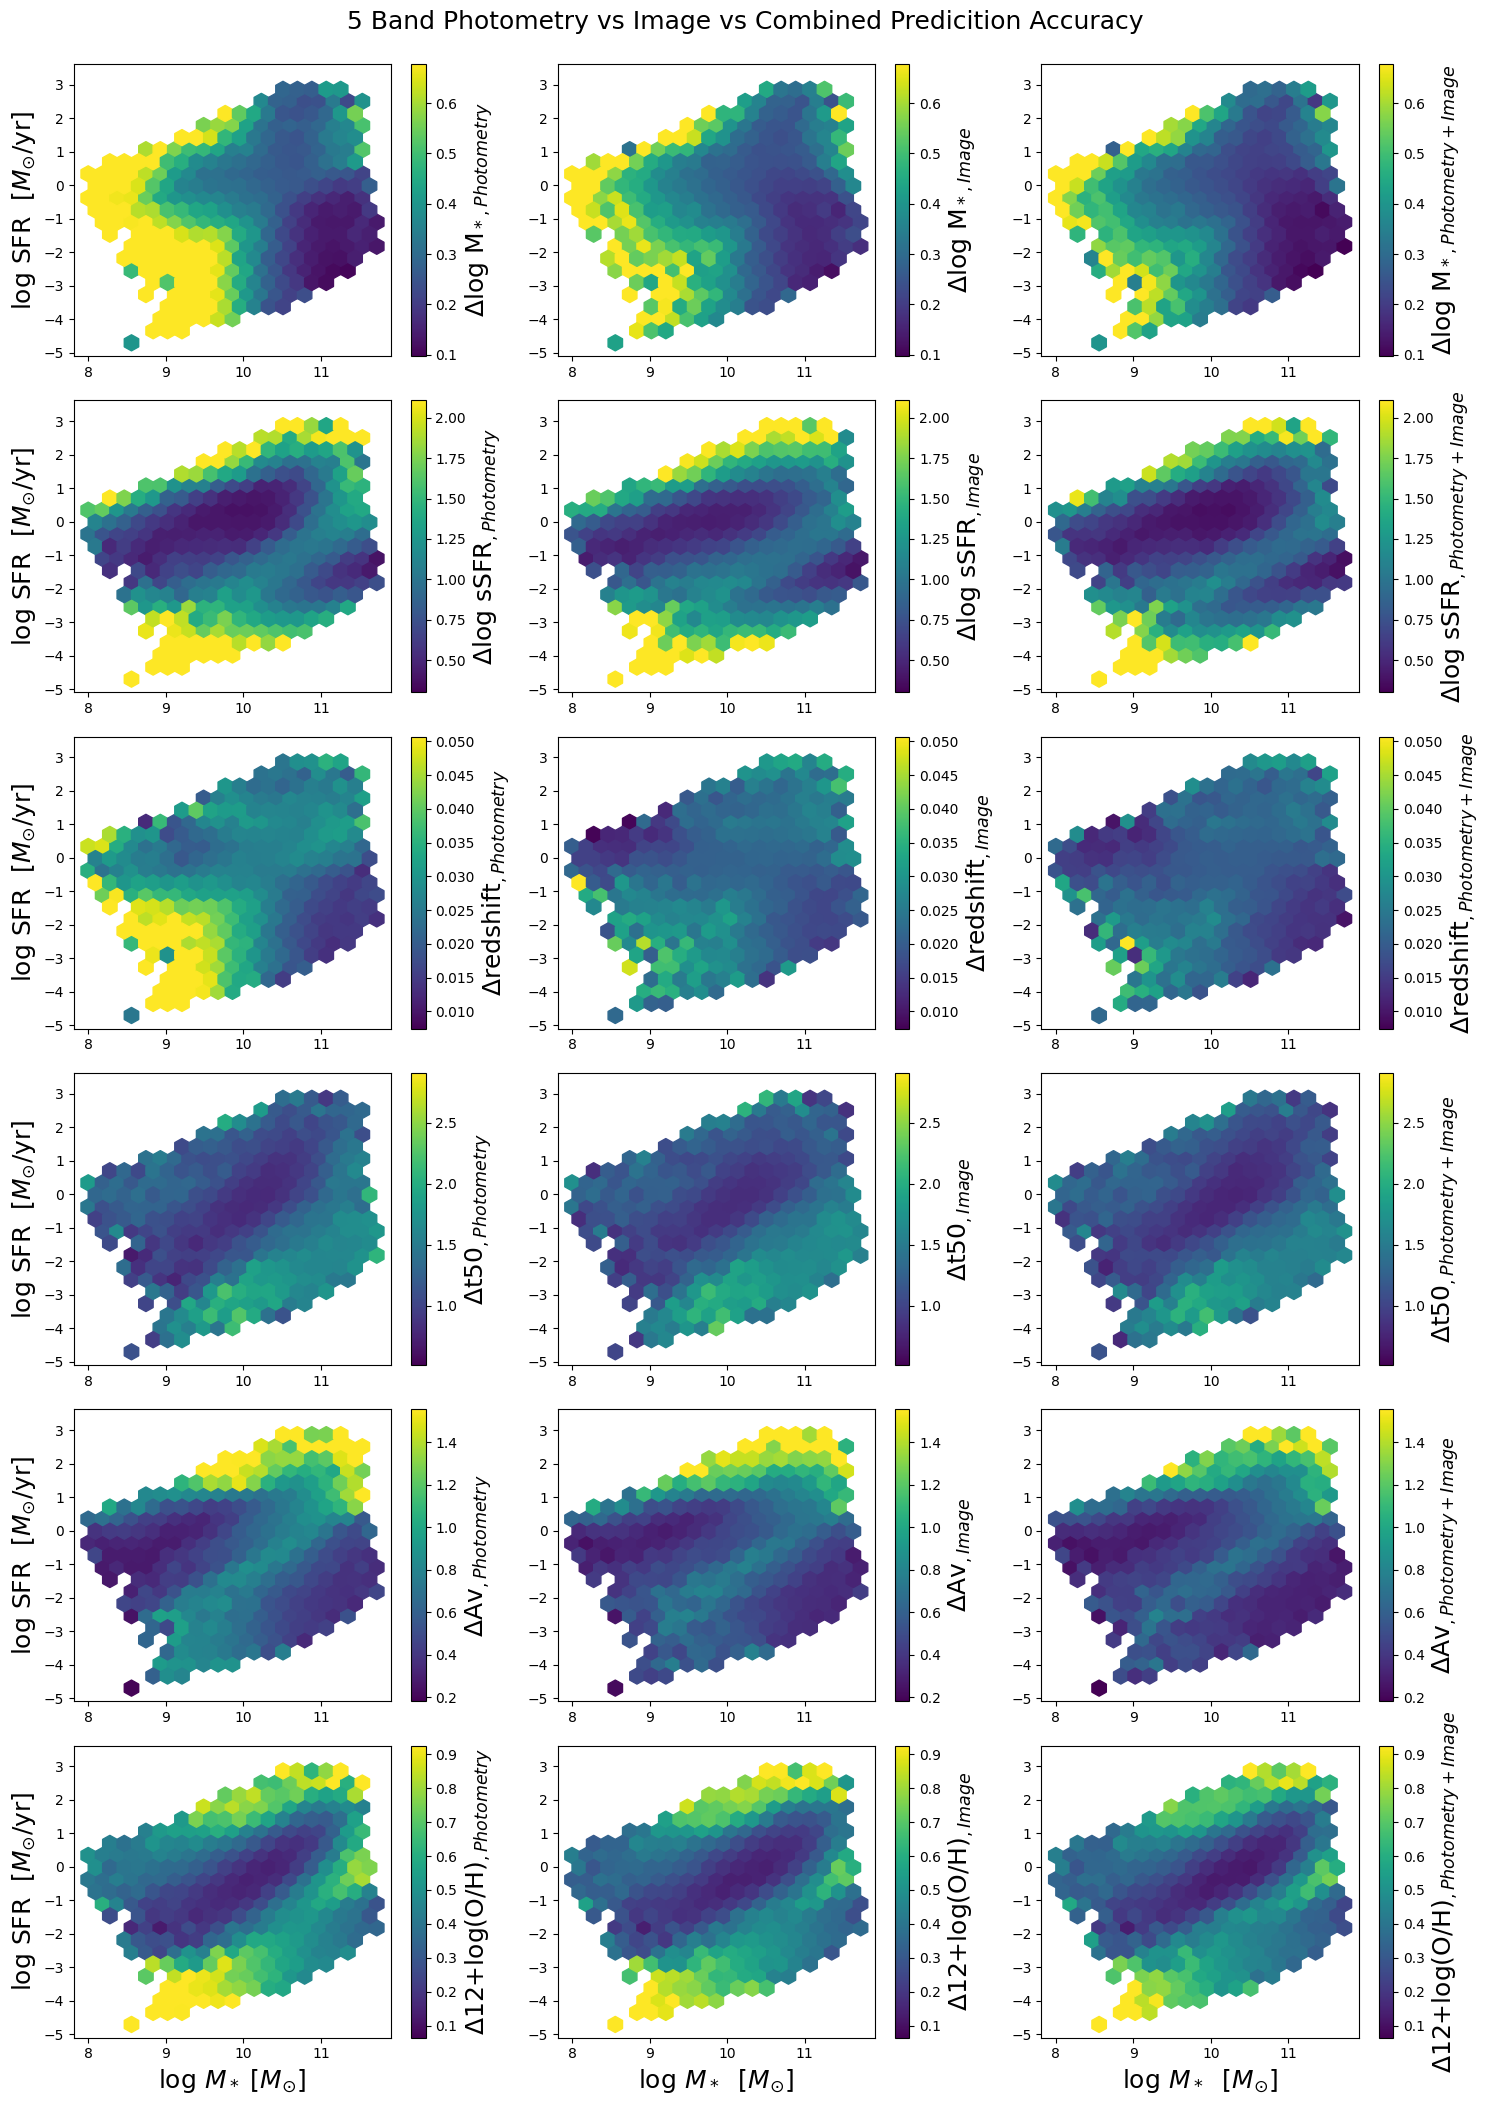

In [121]:
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','12+log(O/H)']

mvals = theta[train_index:,0]
sfrvals = theta[train_index:,1] + theta[train_index:,0] - 9

a = 9.5
b = a *1.294

plt.subplots(figsize=(15,21),nrows=6, ncols=3)
plt.suptitle('5 Band Photometry vs Image vs Combined Predicition Accuracy',fontsize=18, y=1)
for qty in range(6):
    c_lower_bound = np.percentile(allimerr[:,qty],2)
    c_upper_bound = np.percentile(allimerr[:,qty],98)
    plt.subplot(6,3,qty*3+1)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_5_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$ [$M_{\odot}$]',fontsize=18) 
    plt.ylabel('log SFR  [$M_{\odot}$/yr]',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Photometry}$',fontsize=18)
    
    plt.subplot(6,3,qty*3+2)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$  [$M_{\odot}$]',fontsize=18)  
    # plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Image}$',fontsize=18)
    plt.tight_layout()

    plt.subplot(6,3,qty*3+3)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_combined_5_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$  [$M_{\odot}$]',fontsize=18) 
    # plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Photometry+Image}$',fontsize=18)

plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/5_bands_SED_vs_image_vs_combined.pdf', dpi=300, bbox_inches='tight')


# for qty in range(6):
#     c_lower_bound = np.percentile(allimerr[:,qty],2)
#     c_upper_bound = np.percentile(allimerr[:,qty],98)
#     plt.figure(figsize=(14,5))
#     plt.subplot(1,2,1)
#     plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_5_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
#     plt.xlabel('log Stellar Mass',fontsize=18); plt.ylabel('log SFR',fontsize=18)
#     clbr = plt.colorbar()
#     templim = plt.gci().get_clim()
#     clbr.set_label('$\Delta$'+labels[qty]+'$_{,SED}$',fontsize=18)
#     plt.subplot(1,2,2)
#     plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
#     plt.xlabel('log Stellar Mass',fontsize=18); plt.ylabel('log SFR',fontsize=18)
#     clbr = plt.colorbar()
#     clbr.set_label('$\Delta$'+labels[qty]+'$_{,Image}$',fontsize=18)
#     plt.tight_layout()
#     plt.show()

11 Band Photometry Accuracy

In [ ]:
from sklearn.metrics import r2_score
train_index = int(0.8*len(gswlc_data))
gal_ids = np.arange(train_index, len(gswlc_data))
ranges = [(9,12),(-15,-8),(0,1.0),(0,13.7),(0,3),(7.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

posteriors = all_samples_sed
# posteriors = []
truths = []

for gid in tqdm(gal_ids):
    # x = eleven_bands_SED
    # xobs = x[gid]
    # posterior_samples = posterior_ensemble_sed.sample((1000,), torch.Tensor(xobs).to(device), show_progress_bars=False)
    # posterior_samples = posterior_samples.cpu().numpy()
    # posteriors.append(np.array(posterior_samples))
    truths.append(theta[gid])

truth_array = np.array(truths)
truth_array.shape

for i in range(truth_array.shape[1]):
    plt.figure(figsize=(4,4))
    xax = truth_array[:,i]
    if labels[i] == 'log M$_*$':
        xax[xax > 12] = 12
    # if labels[i] == 'log sSFR':
    #     xax[xax>-7] = -7
    #     xax[xax<-15] = -15
    yax = np.array([np.nanpercentile(posteriors[j][:,i],50) for j in range(len(posteriors))])
    yax_lo = np.array([np.nanpercentile(posteriors[j][:,i],16) for j in range(len(posteriors))])
    yax_hi = np.array([np.nanpercentile(posteriors[j][:,i],84) for j in range(len(posteriors))])
    wts = ((np.nanmax(xax)-np.nanmin(xax))/(yax_hi-yax_lo))**2*1
    rsq = r2_score(xax, yax)
    bias = np.nanmedian(xax-yax)
    var = np.sqrt(np.nanstd((xax-yax)**2))
    plt.scatter(xax, yax, s = wts, c = wts, cmap='Spectral')
    # plt.scatter(xax,yax)
    plt.xlabel(labels[i]+' [true]',fontsize=18)
    plt.ylabel(labels[i]+' [pred]',fontsize=18)
    plt.plot([np.nanmin(xax), np.nanmax(xax)],[np.nanmin(xax), np.nanmax(xax)],'k--')
    xrange = np.nanmax(xax) - np.nanmin(xax)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.1*xrange, '$R^2: %.2f$' %rsq, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.2*xrange, '$\mu: %.2f$' %bias, fontsize=14)
    plt.text(np.nanmin(xax) + 0.03*xrange, np.nanmax(xax) -0.3*xrange, '$\sigma: %.2f$' %var, fontsize=14)
    plt.show()

In [ ]:
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','Z']

mvals = theta[train_index:,0]
sfrvals = theta[train_index:,1] + theta[train_index:,0] - 9

a = 9.5
b = a *1.294

plt.subplots(figsize=(9,21),nrows=6, ncols=2)
plt.suptitle('Half-Size Image vs Full Image Predicition Accuracy',fontsize=18, y=1)
for qty in range(6):
    c_lower_bound_a = np.percentile(allimerr_half_size[:,qty],2)
    c_upper_bound_a = np.percentile(allimerr_half_size[:,qty],98)

    c_lower_bound_b = np.percentile(allimerr[:,qty],2)
    c_upper_bound_b = np.percentile(allimerr[:,qty],98)
    plt.subplot(6,2,qty*2+1)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr_half_size[:,qty], vmin=c_lower_bound_a, vmax=c_upper_bound_a, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$',fontsize=18) 
    plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Half-Size Image}$',fontsize=18)
    plt.subplot(6,2,qty*2+2)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr[:,qty], vmin=c_lower_bound_a, vmax=c_upper_bound_a, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$',fontsize=18)  
    # plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Image}$',fontsize=18)
    plt.tight_layout()

plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/half_sized_image_vs_full_image.pdf', dpi=300, bbox_inches='tight')

# Figure 3

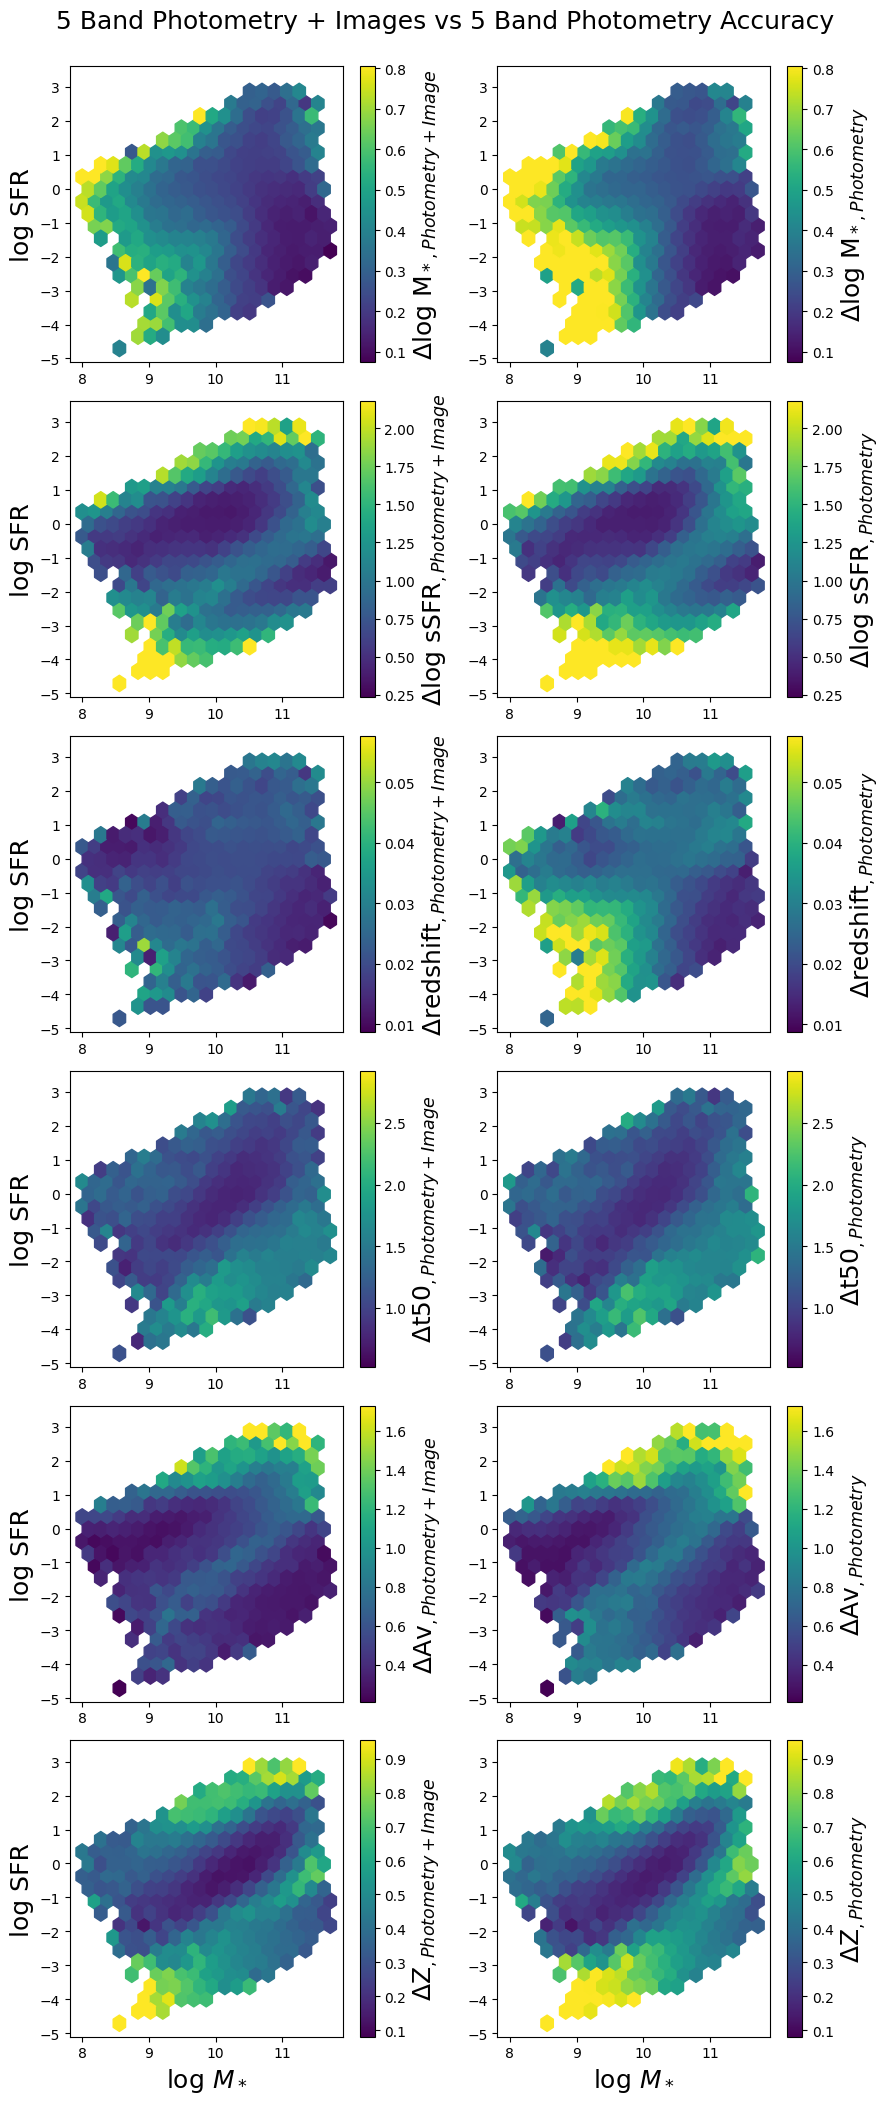

In [105]:
plt.subplots(figsize=(9,21),nrows=6, ncols=2)
plt.suptitle('5 Band Photometry + Images vs 5 Band Photometry Accuracy',fontsize=18, y=1)
for qty in range(6):
    c_lower_bound = np.percentile(allsederr_5_bands[:,qty],2)
    c_upper_bound = np.percentile(allsederr_5_bands[:,qty],98)
    plt.subplot(6,2,qty*2+1)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_combined_5_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$',fontsize=18) 
    plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Photometry+Image}$',fontsize=18)
    plt.subplot(6,2,qty*2+2)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_5_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$',fontsize=18)  
    # plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Photometry}$',fontsize=18)
    plt.tight_layout()

plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/combined_5_band_vs_5_band_photometry.pdf', dpi=300, bbox_inches='tight')

# Figure 4

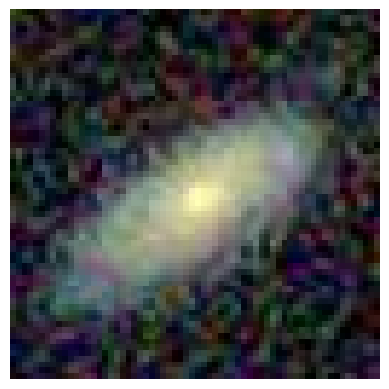

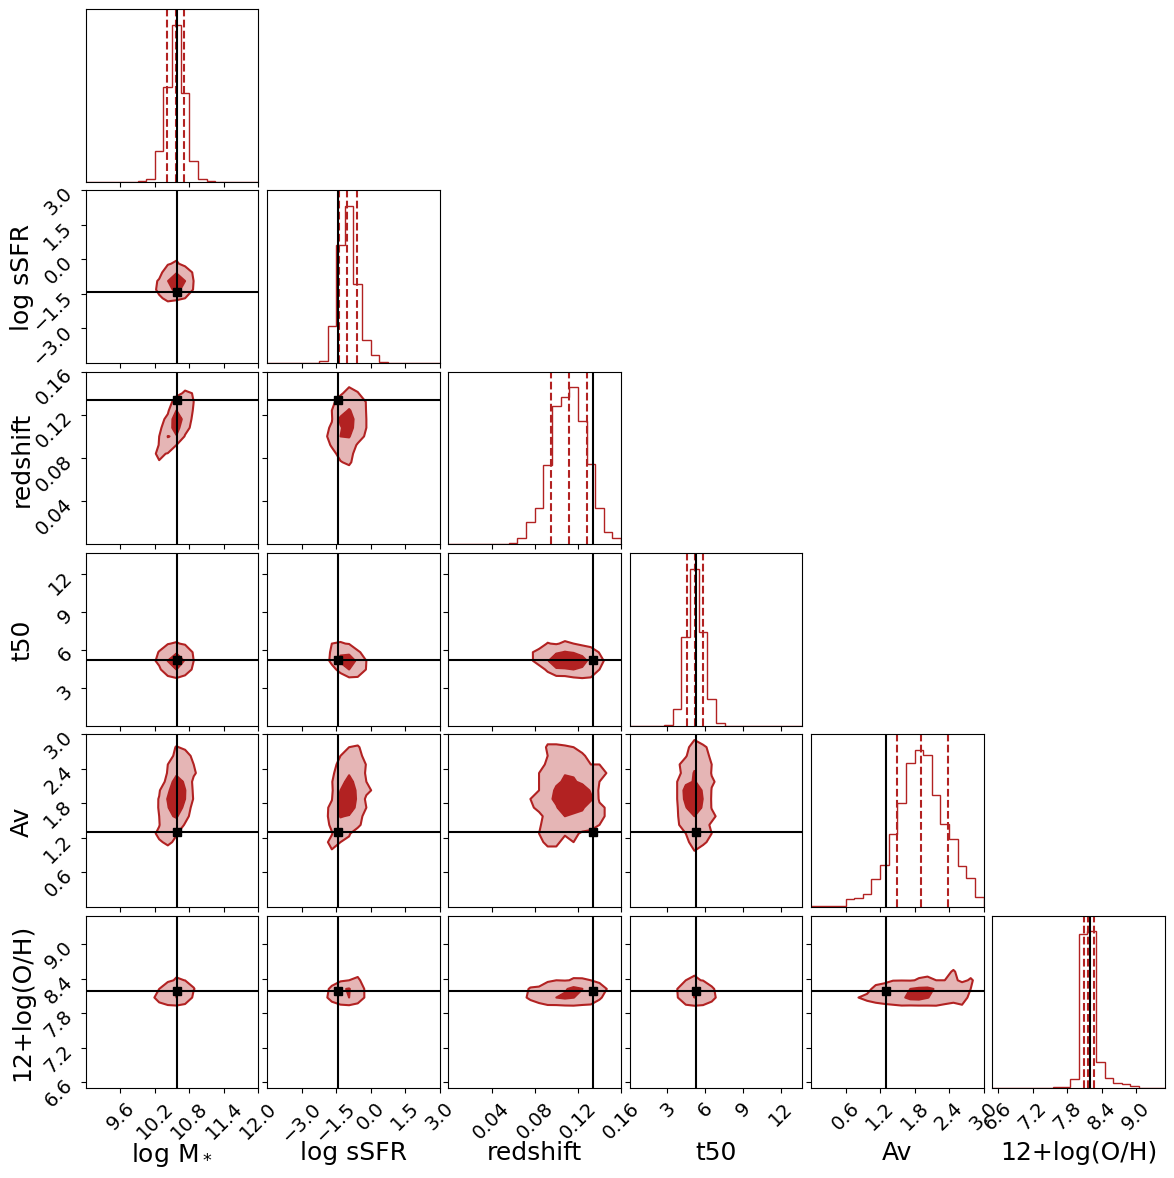

In [123]:
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-4.5,3),(0,0.16),(0,13.7),(0,3),(6.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','12+log(O/H)']

np.random.seed(256)
random_gal = np.random.randint(train_index, len(gswlc_data), size=(1))
random_gal = np.array(random_gal[0],dtype=int)

gid = random_gal

xobs_im = gswlc_embeds[gid,:]
x_truth = theta[gid,:]

posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
posterior_samples_im = posterior_samples_im.cpu().numpy()

plt.imshow(Image.open(io.BytesIO(gswlc_images[gid])))
plt.axis('off')

fig = corner.corner(posterior_samples_im, truths=x_truth, truth_color='k',color='firebrick',range=ranges,labels=labels, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig.set_size_inches(12,12)
#adjust font size
for label in fig.get_axes():
    label.xaxis.label.set_size(18)
    label.yaxis.label.set_size(18)
    for tick in label.get_xticklabels():
        tick.set_fontsize(14)
    for tick in label.get_yticklabels():
        tick.set_fontsize(14)
plt.show()

# Figure 5

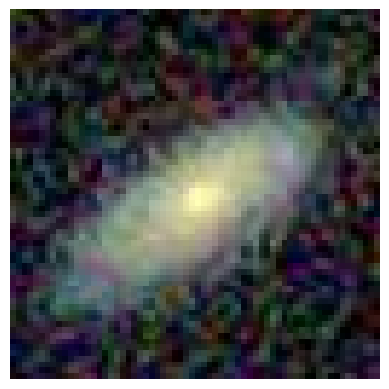

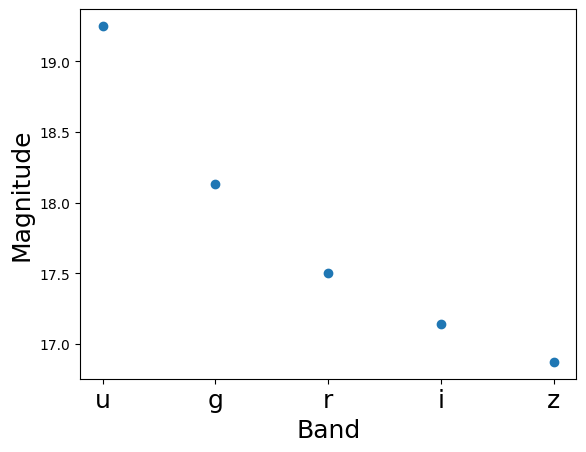

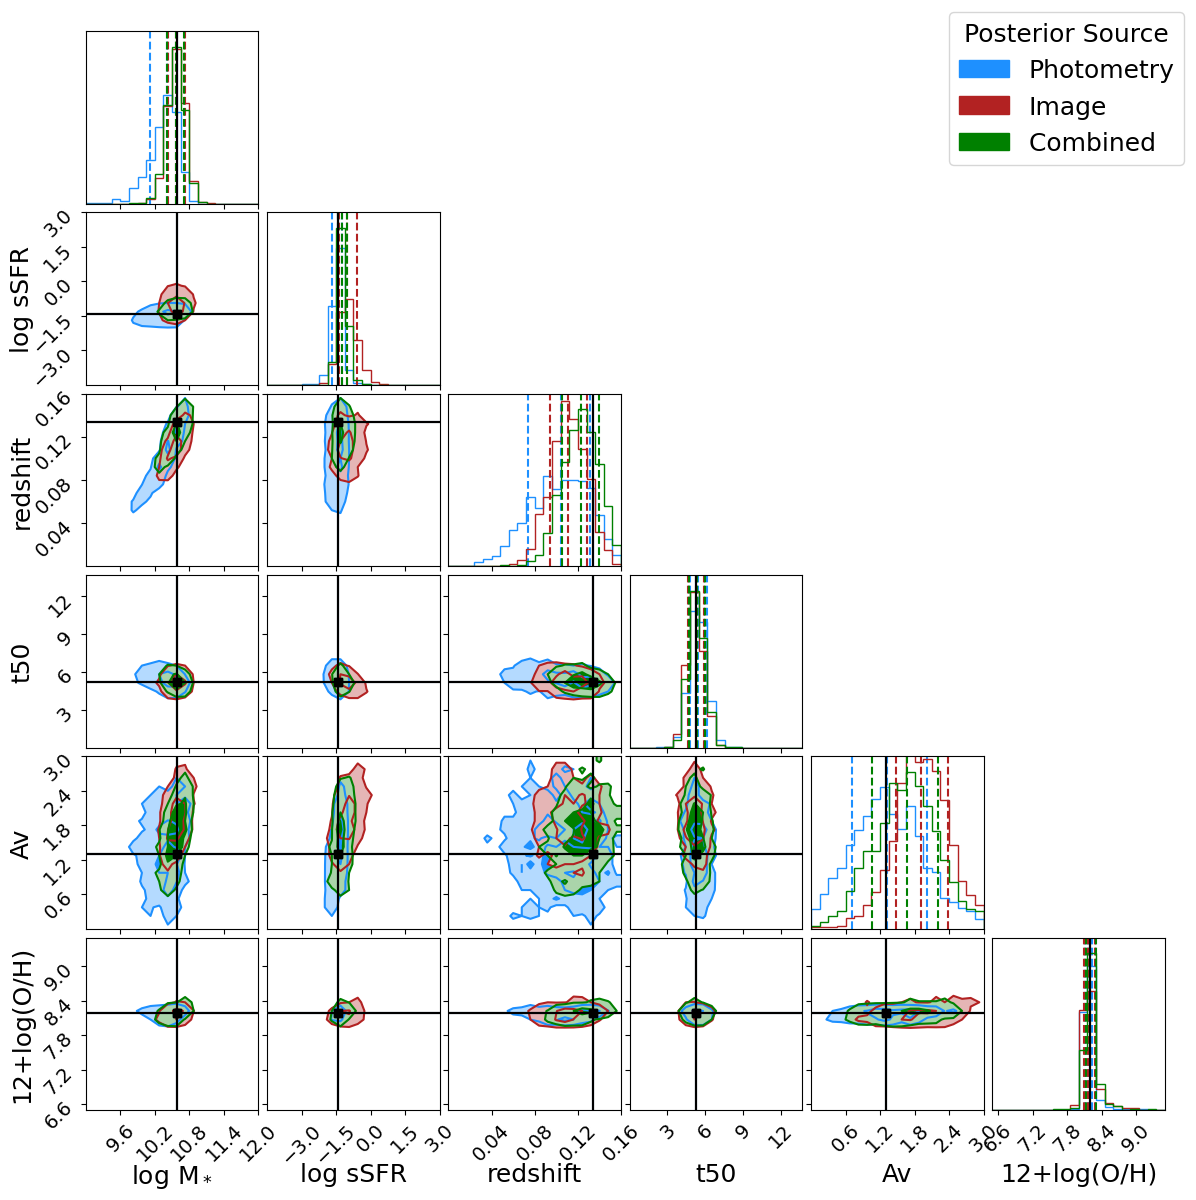

In [124]:
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-4.5,3),(0,0.16),(0,13.7),(0,3),(6.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','12+log(O/H)']


np.random.seed(256)
random_gal = np.random.randint(train_index, len(gswlc_data), size=(1))
random_gal = np.array(random_gal[0],dtype=int)

gid = random_gal
xobs_sed = five_bands_SED[gid,:]
xobs_im = gswlc_embeds[gid,:]
x_truth = theta[gid,:]

posterior_samples_sed = posterior_ensemble_sed_5_bands.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
posterior_samples_sed = posterior_samples_sed.cpu().numpy()


posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
posterior_samples_im = posterior_samples_im.cpu().numpy()

posterior_samples_combined = posterior_ensemble_combined_5_bands.sample((1000,), torch.Tensor(np.hstack((xobs_im,xobs_sed))).to(device), show_progress_bars = False)
posterior_samples_combined = posterior_samples_combined.cpu().numpy()

plt.imshow(Image.open(io.BytesIO(gswlc_images[gid])))
plt.axis('off')
plt.figure()
plt.scatter(np.arange(5),xobs_sed)
plt.xticks(np.arange(0,5),['u','g','r','i','z'],fontsize=18)
plt.xlabel('Band',fontsize=18)
plt.ylabel('Magnitude',fontsize=18)
fig = corner.corner(posterior_samples_sed, truths=x_truth,color='dodgerblue',range=ranges,labels=labels, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig = corner.corner(posterior_samples_im, truths=x_truth, truth_color='k',color='firebrick',range=ranges,labels=labels,fig=fig, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig = corner.corner(posterior_samples_combined, truths=x_truth, truth_color='k',color='green',range=ranges,labels=labels,fig=fig, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
import matplotlib.patches as mpatches
sed_legend_patch = mpatches.Patch(color='dodgerblue', label='Photometry')
image_legend_patch = mpatches.Patch(color='firebrick', label='Image')
combined_legend_patch = mpatches.Patch(color='green', label='Combined ')
fig.legend(handles=[sed_legend_patch, image_legend_patch, combined_legend_patch],
           loc='upper right', # Try different locations e.g. 'center left', 'lower center'
           fontsize='18', # Or a specific number like 10 or 12
           title='Posterior Source', # Optional title for the legend
           frameon=True,
           title_fontsize ='18') # Optional: draw a frame around the legend
fig.set_size_inches(12,12)
#adjust font size
for label in fig.get_axes():
    label.xaxis.label.set_size(18)
    label.yaxis.label.set_size(18)
    for tick in label.get_xticklabels():
        tick.set_fontsize(14)
    for tick in label.get_yticklabels():
        tick.set_fontsize(14)
plt.show()

# Figure 6

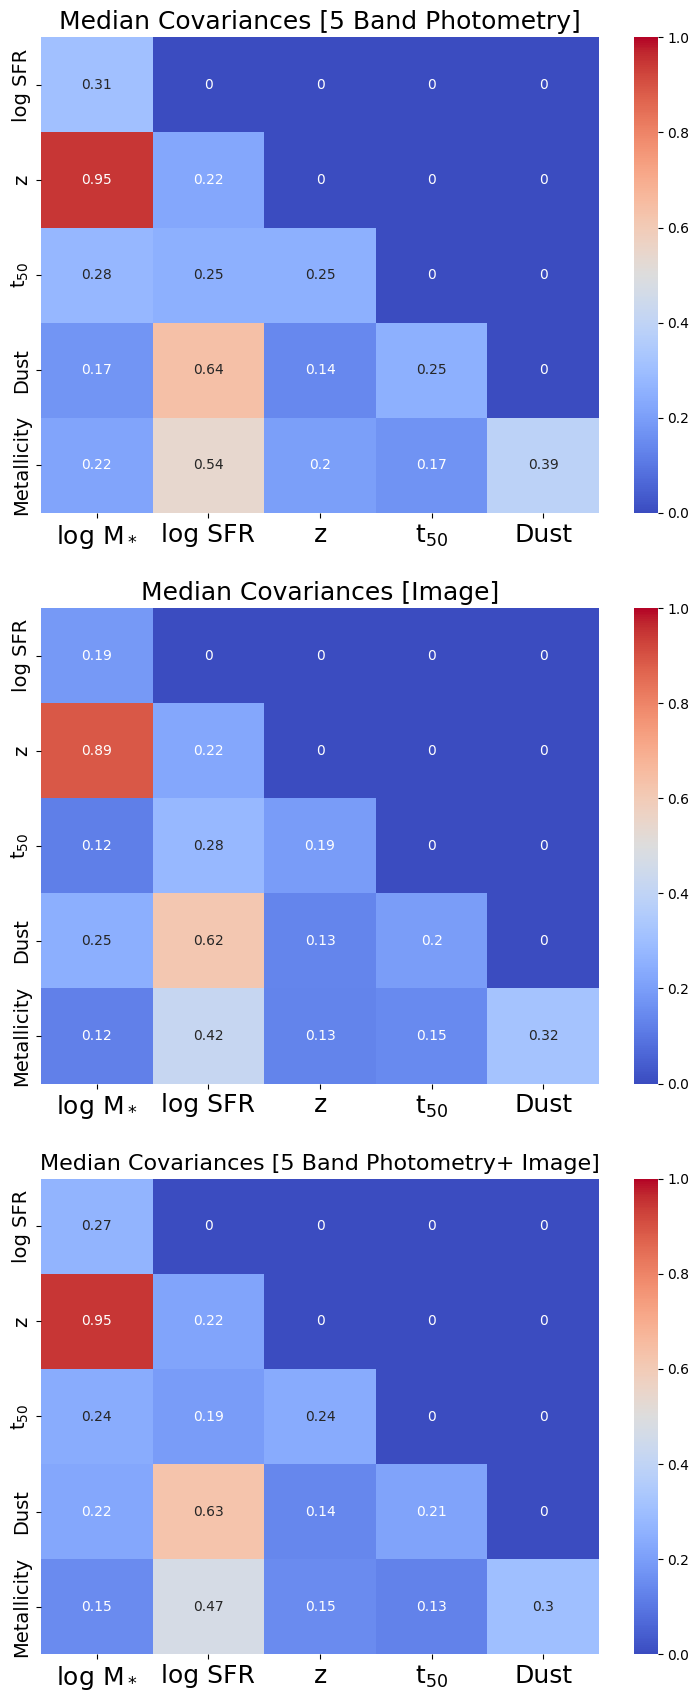

In [178]:
import seaborn as sns
labels = ['log M$_*$', 'log SFR','z','t$_{50}$','Dust','Metallicity']

plt.figure(figsize=(9,21))
plt.subplot(3,1,1)

sns.heatmap(np.nanmedian(np.abs(cov_array_sed_5_bands),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=18)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=14)
plt.title('Median Covariances [5 Band Photometry]',fontsize=18)
 
plt.subplot(3,1,2)

sns.heatmap(np.nanmedian(np.abs(cov_array_im),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=18)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=14)
plt.title('Median Covariances [Image]',fontsize=18)

plt.subplot(3,1,3)

sns.heatmap(np.nanmedian(np.abs(cov_array_combined_5_bands),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=18)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=14)
plt.title('Median Covariances [5 Band Photometry+ Image]',fontsize=16)

# plt.tight_layout()
plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/5_bands_SED_vs_image_covariance.pdf', dpi=300, bbox_inches='tight')
plt.show()

# plt.figure(figsize=(9*2,7))
# plt.subplot(1,2,1)

# sns.heatmap(np.nanstd(np.abs(target_sed),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
# plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
# plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
# plt.title('std covariances [SED]',fontsize=18)

# plt.subplot(1,2,2)

# sns.heatmap(np.nanstd(np.abs(cov_array_im),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
# plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
# plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
# plt.title('std covariances [Image]',fontsize=18)

# plt.tight_layout()
# plt.show()

# Figure 7

66 0.03852889667250438
3.66
4.205


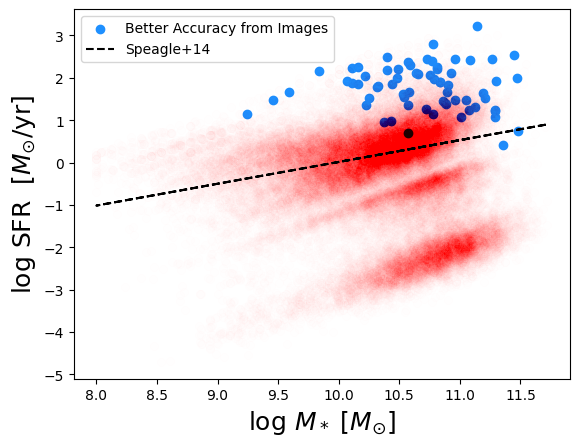

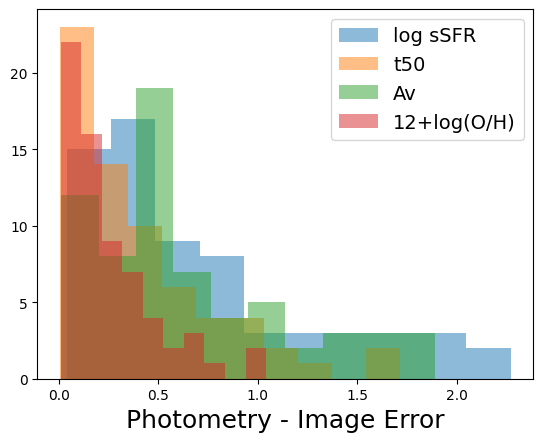

In [131]:
#Very Dusty Galaxies
better_img = np.where((np.array(theta)[train_index:][:,4]>3.5)  & (allsederr_5_bands[:,1]-allimerr_5_bands[:,1]>0)  & (allsederr_5_bands[:,3]-allimerr_5_bands[:,3]>0) & (allsederr_5_bands[:,4]-allimerr_5_bands[:,4]>0) & (allsederr_5_bands[:,5]-allimerr_5_bands[:,5]>0))[0]
better_sed = np.where((np.array(theta)[train_index:][:,4]>3.5) & (allsederr_5_bands[:,1]-allimerr_5_bands[:,1]<0) & (allsederr_5_bands[:,3]-allimerr_5_bands[:,3]<0) & (allsederr_5_bands[:,4]-allimerr_5_bands[:,4]<0) & (allsederr_5_bands[:,5]-allimerr_5_bands[:,5]<0))[0]
print(len(better_img), len(better_img)/len(np.where(theta[train_index:][:,4]>3)[0]))
plt.scatter(mvals[better_img], sfrvals[better_img], color='dodgerblue', alpha=1, label='Better Accuracy from Images')
# plt.scatter(mvals[better_sed], sfrvals[better_sed], color='green', alpha=1)
plt.scatter(mvals, sfrvals, color='red', alpha=0.005)
plt.plot(mvals, (0.84-0.026*12.5)*mvals - (6.51-0.11*12.5), color='k', linestyle='--', label='Speagle+14')
plt.xlabel('log $M_*$ [$M_{\odot}$]',fontsize=18)
plt.ylabel('log SFR  [$M_{\odot}$/yr]',fontsize=18)
plt.legend(loc='upper left', fontsize=10)

plt.figure()
for i in ([1,3,4,5]):
    plt.hist(allsederr_5_bands[:,i][better_img]-allimerr[:,i][better_img], label=labels[i], alpha=0.5)
plt.legend(loc='upper right', fontsize=14)
plt.xlabel('Photometry - Image Error',fontsize=18)
# print(len(np.where(allsederr[:,1][better_img]-allimerr[:,1][better_img]>0)[0]))
print(np.nanmean(sersic_n[better_img]))
print(np.nanmean(sersic_n[better_sed]))

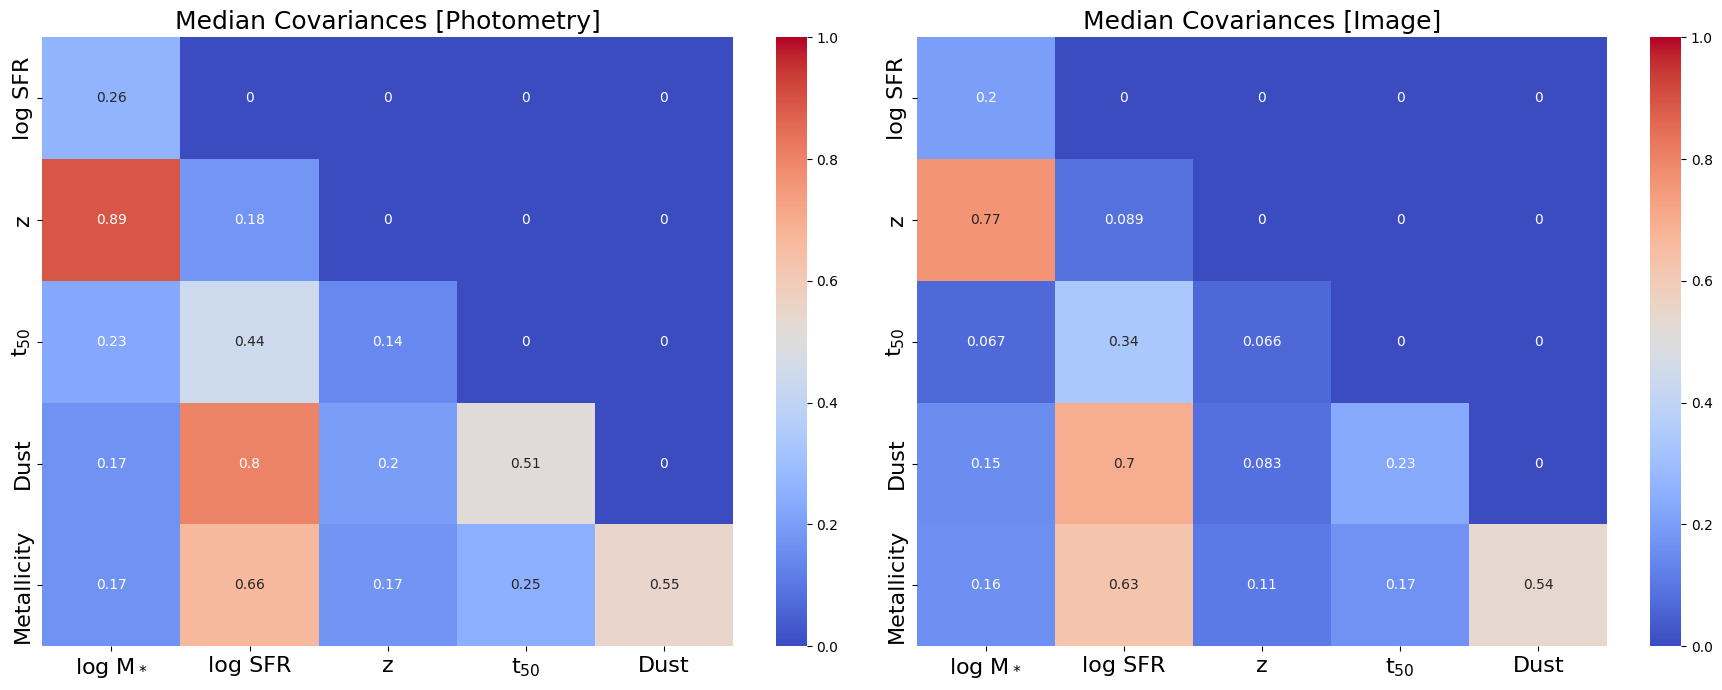

In [209]:
import seaborn as sns
labels = ['log M$_*$', 'log SFR','z','t$_{50}$','Dust','Metallicity']

plt.figure(figsize=(9*2,7))
plt.subplot(1,2,1)

sns.heatmap(np.nanmedian(np.abs(cov_array_sed_5_bands[better_img]),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
plt.title('Median Covariances [Photometry]',fontsize=18)
 
plt.subplot(1,2,2)

sns.heatmap(np.nanmedian(np.abs(cov_array_im[better_img]),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
plt.title('Median Covariances [Image]',fontsize=18)

plt.tight_layout()
plt.show()

# plt.figure(figsize=(9*2,7))
# plt.subplot(1,2,1)

# sns.heatmap(np.nanstd(np.abs(target_sed),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
# plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
# plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
# plt.title('std covariances [SED]',fontsize=18)

# plt.subplot(1,2,2)

# sns.heatmap(np.nanstd(np.abs(cov_array_im[better_img]),0), cmap='coolwarm',vmin=0., vmax=1., annot=True , cbar=True)
# plt.xticks(np.arange(5)+0.5, labels[0:5], fontsize=16)
# plt.yticks(np.arange(5)+0.5, labels[1:], fontsize=16)
# plt.title('std covariances [Image]',fontsize=18)

# plt.tight_layout()
# plt.show()

In [191]:
len(better_img)

66

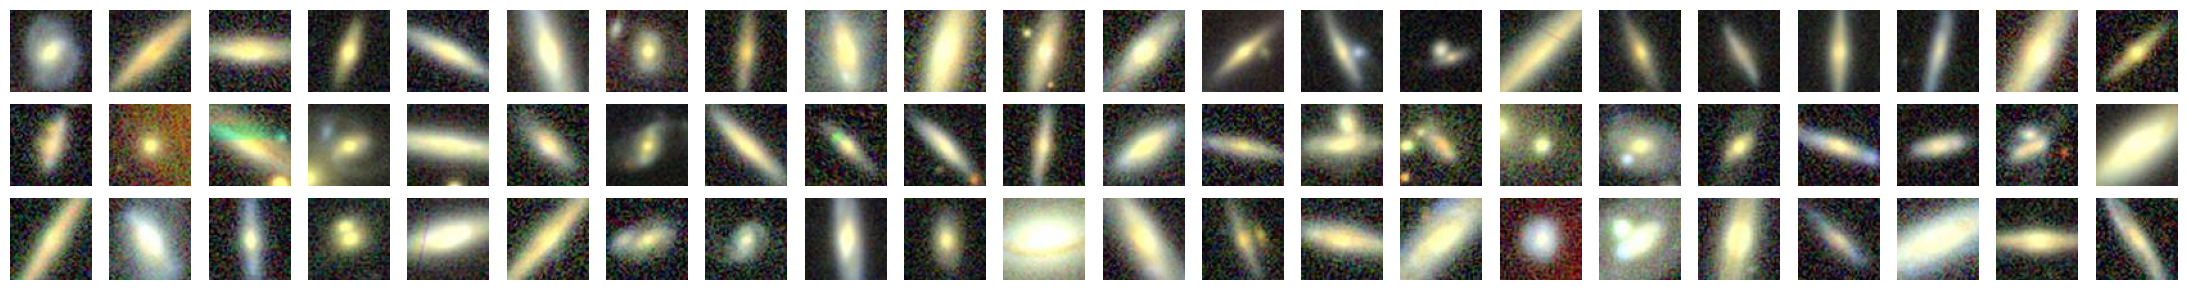

In [208]:
selected_sample = better_img
# plt.subplots(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),figsize=(20,20))
plt.subplots(3,22,figsize=(22,3))
for i in range(len(selected_sample)):
    j = selected_sample[i] + train_index
    # plt.subplot(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),i+1)
    plt.subplot(3,22,i+1)
    # plt.title('Sersic n: '+str(sersic_n[j-train_index])[0:4])
    # plt.title('Pmerger: '+str(pmerger[j-train_index])[0:4])
    plt.imshow(Image.open(io.BytesIO(gswlc_images[j])))
    plt.axis('off')
        # plt.show()
plt.tight_layout()

plt.show();

# Figure 8

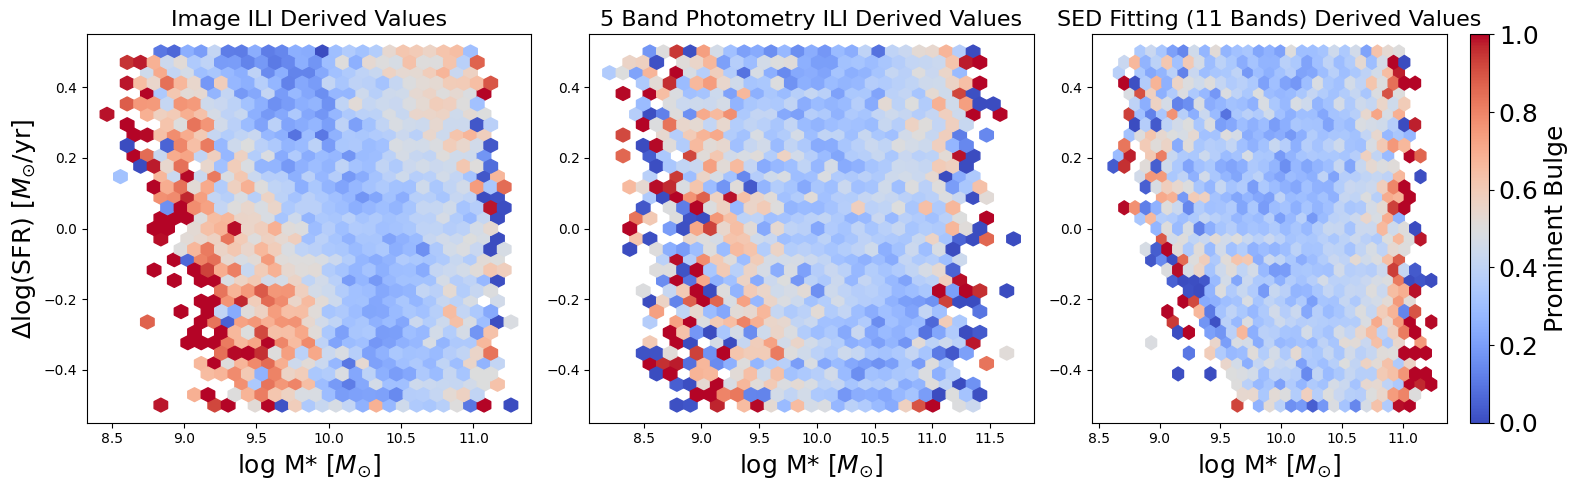

In [167]:
lower_bound_mass = 10
upper_mound_mass = 11

main_sequence_sfr_sed = (0.84-0.026*12.5)*allsedpred_5_bands[:,0] - (6.51-0.11*12.5)
main_sequence_sfr_im = (0.84-0.026*12.5)*allimpred[:,0] - (6.51-0.11*12.5)
main_sequence_sfr_true= (0.84-0.026*12.5)*theta[train_index:,0] - (6.51-0.11*12.5)

sfr_vals_im = allimpred[:,1]+allimpred[:,0]-9
sfr_vals_sed = allsedpred_5_bands[:,1]+allsedpred_5_bands[:,0]-9
sfr_vals_true = theta[train_index:,1]+theta[train_index:,0]-9

mvals_im= allimpred[:,0]
mvals_sed = allsedpred_5_bands[:,0]
mvals_true = theta[train_index:,0]


mask_sed = np.where((sfr_vals_sed>=main_sequence_sfr_sed-0.5)&((sfr_vals_sed<=main_sequence_sfr_sed+0.5)))[0]


mask_im = np.where((sfr_vals_im>=main_sequence_sfr_im-0.5)&((sfr_vals_im<=main_sequence_sfr_im+0.5)))[0]


mask_true = np.where((sfr_vals_true>=main_sequence_sfr_true-0.5)&((sfr_vals_true<=main_sequence_sfr_true+0.5)))[0]

#Calculate scatter from sfms for 11 band SED and images
scatter_5_band_sed = sfr_vals_sed - main_sequence_sfr_sed
scatter_im = sfr_vals_im - main_sequence_sfr_im
scatter_true = sfr_vals_true - main_sequence_sfr_true

mass_bins = np.arange(8.5,11,0.4)

pbulge_masked_im = pbulge[mask_im]
pbulge_masked_true = pbulge[mask_true]
pbulge_masked_sed = pbulge[mask_sed]

# Use fig, axes for better subplot management
fig, axes = plt.subplots(figsize=(16,5),nrows=1, ncols=3)

# Subplot 1
axes[0].set_title('Image ILI Derived Values',fontsize=16)
hb1 = axes[0].hexbin(mvals_im[mask_im], scatter_im[mask_im], C=pbulge_masked_im, gridsize=30, cmap='coolwarm', vmin=0, vmax=1)
# axes[0].vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.5)
# axes[0].hlines(0, 8.5, 11.5, color='black', alpha=0.8, linestyle='--')
axes[0].set_xlabel('log M* [$M_{\odot}$]',fontsize=18)
axes[0].set_ylabel('$\Delta$log(SFR) [$M_{\odot}$/yr]',fontsize=18)
# If you want a colorbar for this subplot:
# cbar1 = fig.colorbar(hb1, ax=axes[0])
# cbar1.set_label('Prominent Bulge', fontsize=18)
# cbar1.ax.tick_params(labelsize=18)

# Subplot 2
axes[1].set_title('5 Band Photometry ILI Derived Values',fontsize=16) # Changed from "Photometery"
hb2 = axes[1].hexbin(mvals_true[mask_true], scatter_true[mask_true], C=pbulge_masked_true, gridsize=30, cmap='coolwarm', vmin=0, vmax=1)
# axes[1].vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.8)
axes[1].set_xlabel('log M* [$M_{\odot}$]',fontsize=18)
# axes[1].set_ylabel('$\Delta$log(SFR) [$M_{\odot}$/yr]',fontsize=18) # Typically omitted for shared axes
# If you want a colorbar for this subplot:
# cbar2 = fig.colorbar(hb2, ax=axes[1])
# cbar2.set_label('Prominent Bulge', fontsize=18)
# cbar2.ax.tick_params(labelsize=18)


# Subplot 3
axes[2].set_title('SED Fitting (11 Bands) Derived Values',fontsize=16)
# Capture the mappable object (PolyCollection) returned by hexbin
hb3 = axes[2].hexbin(mvals_sed[mask_sed], scatter_5_band_sed[mask_sed], C=pbulge_masked_sed, gridsize=30, cmap='coolwarm', vmin=0, vmax=1)
# axes[2].vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.8)
axes[2].set_xlabel('log M* [$M_{\odot}$]',fontsize=18)
# axes[2].set_ylabel('$\Delta$log(SFR) [$M_{\odot}$/yr]',fontsize=18) # Typically omitted for shared axes

# CORRECTED: Pass the mappable object (hb3) to fig.colorbar and specify the axis
cbar = fig.colorbar(hb3, ax=axes[2]) # Associate with the third subplot's axes
cbar.set_label('Prominent Bulge', fontsize=18)
cbar.ax.tick_params(labelsize=18)

plt.tight_layout()
# plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/sfms_scatter.pdf', dpi=300, bbox_inches='tight')
plt.show()

# plt.subplots(figsize=(16,5),nrows=1, ncols=3)

# plt.subplot(1,3,1)
# plt.title('Image ILI Derived Values',fontsize=18)
# plt.hexbin(mvals_im[mask_im],scatter_im[mask_im], C = pbulge[mask_im], gridsize=30, cmap='viridis', vmin=0, vmax=1)
# # plt.vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.5)
# # plt.hlines(0, 8.5, 11.5, color='black', alpha=0.8, linestyle='--')
# plt.xlabel('log M* [$M_{\odot}$]',fontsize=18)
# plt.ylabel('$\Delta$log(SFR) [$M_{\odot}$/yr]',fontsize=18)
# # plt.colorbar(label='Prominent Bulge')


# plt.subplot(1,3,2)
# plt.title('Photometery ILI Derived Values',fontsize=18)
# plt.hexbin(mvals_true[mask_true],scatter_true[mask_true], C = pbulge[mask_true], gridsize=30, cmap='viridis', vmin=0, vmax=1)
# # plt.vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.8)
# plt.xlabel('log M* [$M_{\odot}$]',fontsize=18)
# # plt.ylabel('$\Delta$log(SFR) [$M_{\odot}$/yr]',fontsize=18)
# # plt.colorbar(label='Prominent Bulge')


# plt.subplot(1,3,3)
# plt.title('SED Fitting Derived Values',fontsize=18)
# plt.hexbin(mvals_sed[mask_sed],scatter_5_band_sed[mask_sed], C = pbulge[mask_sed], gridsize=30, cmap='viridis', vmin=0, vmax=1)
# # plt.vlines(mass_bins, -0.6, 0.6, color='black', alpha=0.8)
# plt.xlabel('log M* [$M_{\odot}$]',fontsize=18)
# # plt.ylabel('$\Delta$log(SFR) [$M_{\odot}$/yr]',fontsize=18)
# # plt.colorbar(label='Prominent Bulge', fontsize=18)
# cbar = plt.colorbar(pbulge[mask_sed]) # 'mappable_object' is what your colorbar represents, e.g., an image from plt.imshow()
# cbar.set_label('Prominent Bulge', fontsize=18)
# cbar.ax.tick_params(labelsize=18)  # Font size of colorbar ticks
# plt.tight_layout()

# Figure 9

In [ ]:
merger = np.where(pmerger<=0.1)[0]

selected_sample = merger[:100]
plt.subplots(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),figsize=(20,20))
for i in range(len(selected_sample)):
    j = selected_sample[i] + train_index
    plt.subplot(int(np.sqrt(len(selected_sample))),int(np.sqrt(len(selected_sample))),i+1)
    # plt.title('Sersic n: '+str(sersic_n[j-train_index])[0:4])
    plt.title('Pmerger: '+str(pmerger[j-train_index])[0:4])
    plt.imshow(Image.open(io.BytesIO(gswlc_images[j])))
    plt.axis('off')
        # plt.show()

plt.show();

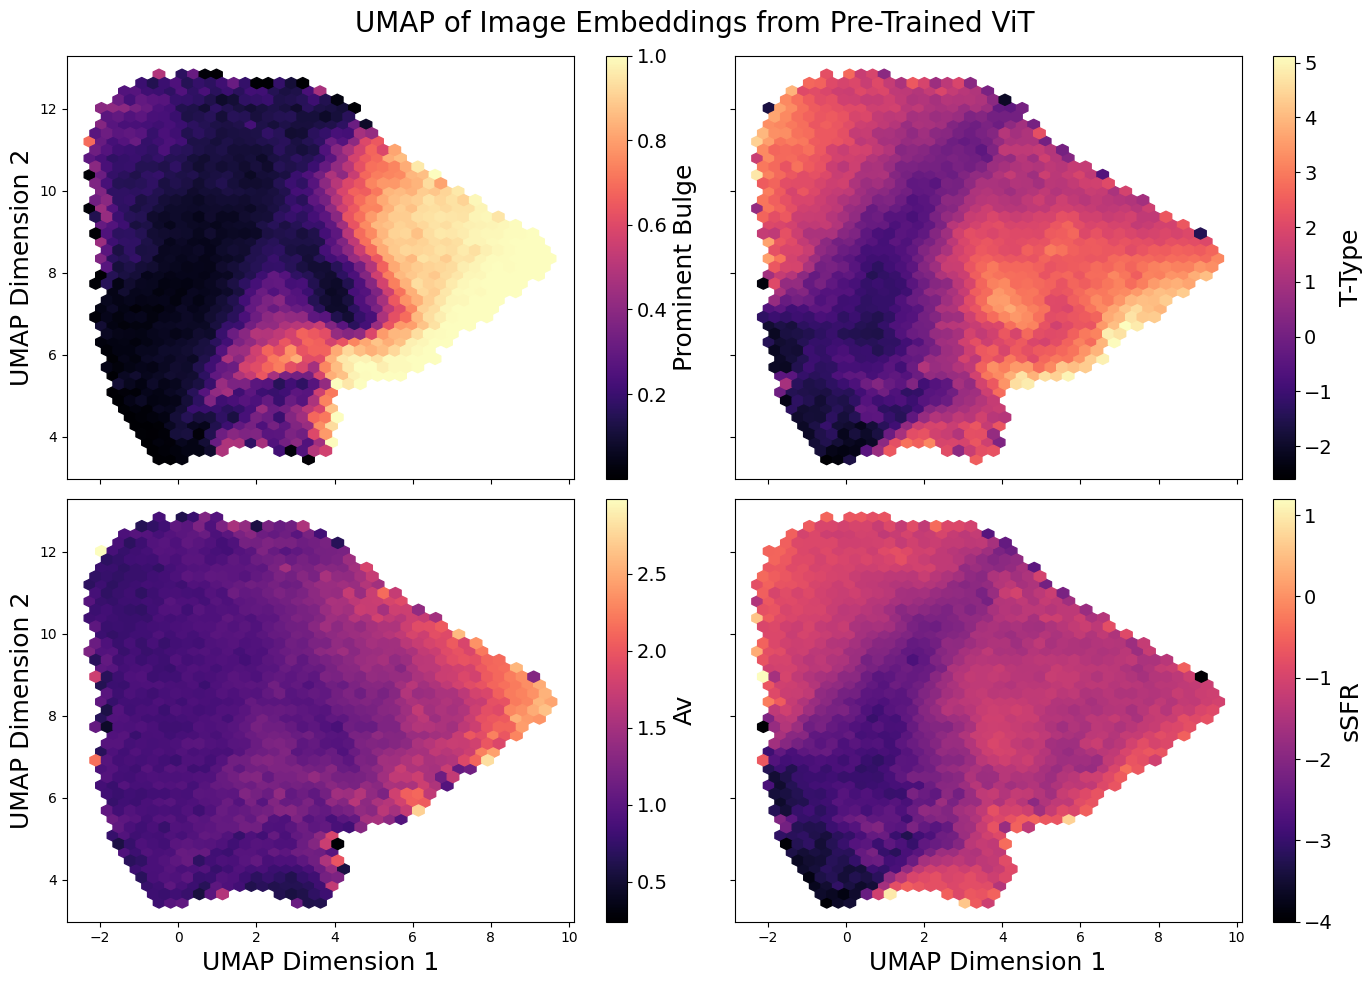

In [170]:
import umap
# data = np.array(gswlc_embeds)
# # Create UMAP reducer
# reducer = umap.UMAP()

# # Fit and transform the data
# embedding = reducer.fit_transform(data)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

# Add a centered title for the entire figure
fig.suptitle('UMAP of Image Embeddings from Pre-Trained ViT', fontsize=20)

# Define common font sizes for consistency
axis_label_fontsize = 18
cbar_label_fontsize = 18 # Matching axis labels, as per previous examples
cbar_tick_fontsize = 14  # Matching axis labels, as per previous examples

# --- Subplot 1 (Top-Left) ---
ax1 = axes[0, 0]
hb1 = ax1.hexbin(embedding[:, 0], embedding[:, 1], C=gswlc_data_merged['pbulge_morph'], gridsize=40, cmap='magma')
ax1.set_ylabel("UMAP Dimension 2", fontsize=axis_label_fontsize)
# No x-label here as it's shared with the plot below
cbar1 = fig.colorbar(hb1, ax=ax1)
cbar1.set_label('Prominent Bulge', fontsize=cbar_label_fontsize)
cbar1.ax.tick_params(labelsize=cbar_tick_fontsize)

# --- Subplot 2 (Top-Right) ---
ax2 = axes[0, 1]
hb2 = ax2.hexbin(embedding[:, 0], embedding[:, 1], C=gswlc_data_merged['ttype_morph'], gridsize=40, cmap='magma')
# No x-label (shared with plot below)
# No y-label (shared with plot to the left)
cbar2 = fig.colorbar(hb2, ax=ax2)
cbar2.set_label('T-Type', fontsize=cbar_label_fontsize)
cbar2.ax.tick_params(labelsize=cbar_tick_fontsize)

# --- Subplot 3 (Bottom-Left) ---
ax3 = axes[1, 0]
hb3 = ax3.hexbin(embedding[:, 0], embedding[:, 1], C=gswlc_data_merged['tauV_50'], gridsize=40, cmap='magma')
ax3.set_xlabel("UMAP Dimension 1", fontsize=axis_label_fontsize)
ax3.set_ylabel("UMAP Dimension 2", fontsize=axis_label_fontsize)
cbar3 = fig.colorbar(hb3, ax=ax3)
cbar3.set_label('Av', fontsize=cbar_label_fontsize)
cbar3.ax.tick_params(labelsize=cbar_tick_fontsize)

# --- Subplot 4 (Bottom-Right) ---
ax4 = axes[1, 1]
hb4 = ax4.hexbin(embedding[:, 0], embedding[:, 1], C=gswlc_data_merged['logSSFR_50'], gridsize=40, cmap='magma')
ax4.set_xlabel("UMAP Dimension 1", fontsize=axis_label_fontsize)
# No y-label (shared with plot to the left)
cbar4 = fig.colorbar(hb4, ax=ax4)
cbar4.set_label('sSFR', fontsize=cbar_label_fontsize)
cbar4.ax.tick_params(labelsize=cbar_tick_fontsize)

# Adjust layout to prevent overlap and ensure suptitle is visible
# The rect parameter [left, bottom, right, top] helps reserve space for suptitle
# fig.tight_layout(rect=[0, 0.03, 1, 0.95])

plt.tight_layout()  

# Save the figure
plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/umap_vit_embeddings.pdf', dpi=300, bbox_inches='tight')

# Display the plot (optional, depending on your environment)
plt.show()

# # Visualize the embedding (if you want 2D)
# plt.subplots(2,2,figsize=(12,9))
# plt.suptitle('UMAP of Image Embeddings from Pre-Trained ViT',fontsize=20)
# plt.subplot(2,2,1)
# plt.hexbin(embedding[:, 0], embedding[:, 1], C = gswlc_data_merged['pbulge_morph'], gridsize=40) 
# plt.xlabel("UMAP Dimension 1",fontsize=18)
# plt.ylabel("UMAP Dimension 2",fontsize=18)
# plt.colorbar(label='Prominent Bulge')

# plt.subplot(2,2,2)
# plt.hexbin(embedding[:, 0], embedding[:, 1], C = gswlc_data_merged['ttype_morph'], gridsize=40)
# plt.xlabel("UMAP Dimension 1",fontsize=18)
# plt.ylabel("UMAP Dimension 2",fontsize=18)
# plt.colorbar(label='T-Type')

# plt.subplot(2,2,3)
# plt.hexbin(embedding[:, 0], embedding[:, 1], C = gswlc_data_merged['tauV_50'], gridsize=40)
# plt.xlabel("UMAP Dimension 1",fontsize=18)
# plt.ylabel("UMAP Dimension 2",fontsize=18)
# plt.colorbar(label='Av')

# plt.subplot(2,2,4)
# plt.hexbin(embedding[:, 0], embedding[:, 1], C = gswlc_data_merged['logSSFR_50'], gridsize=40) #metallicty, age show similar patterns in UMAP space 
# plt.xlabel("UMAP Dimension 1",fontsize=18)
# plt.ylabel("UMAP Dimension 2",  fontsize=18)
# plt.colorbar(label='sSFR')

# plt.tight_layout()
# plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/umap_vit_embeddings.pdf', dpi=300, bbox_inches='tight')

# Appendix

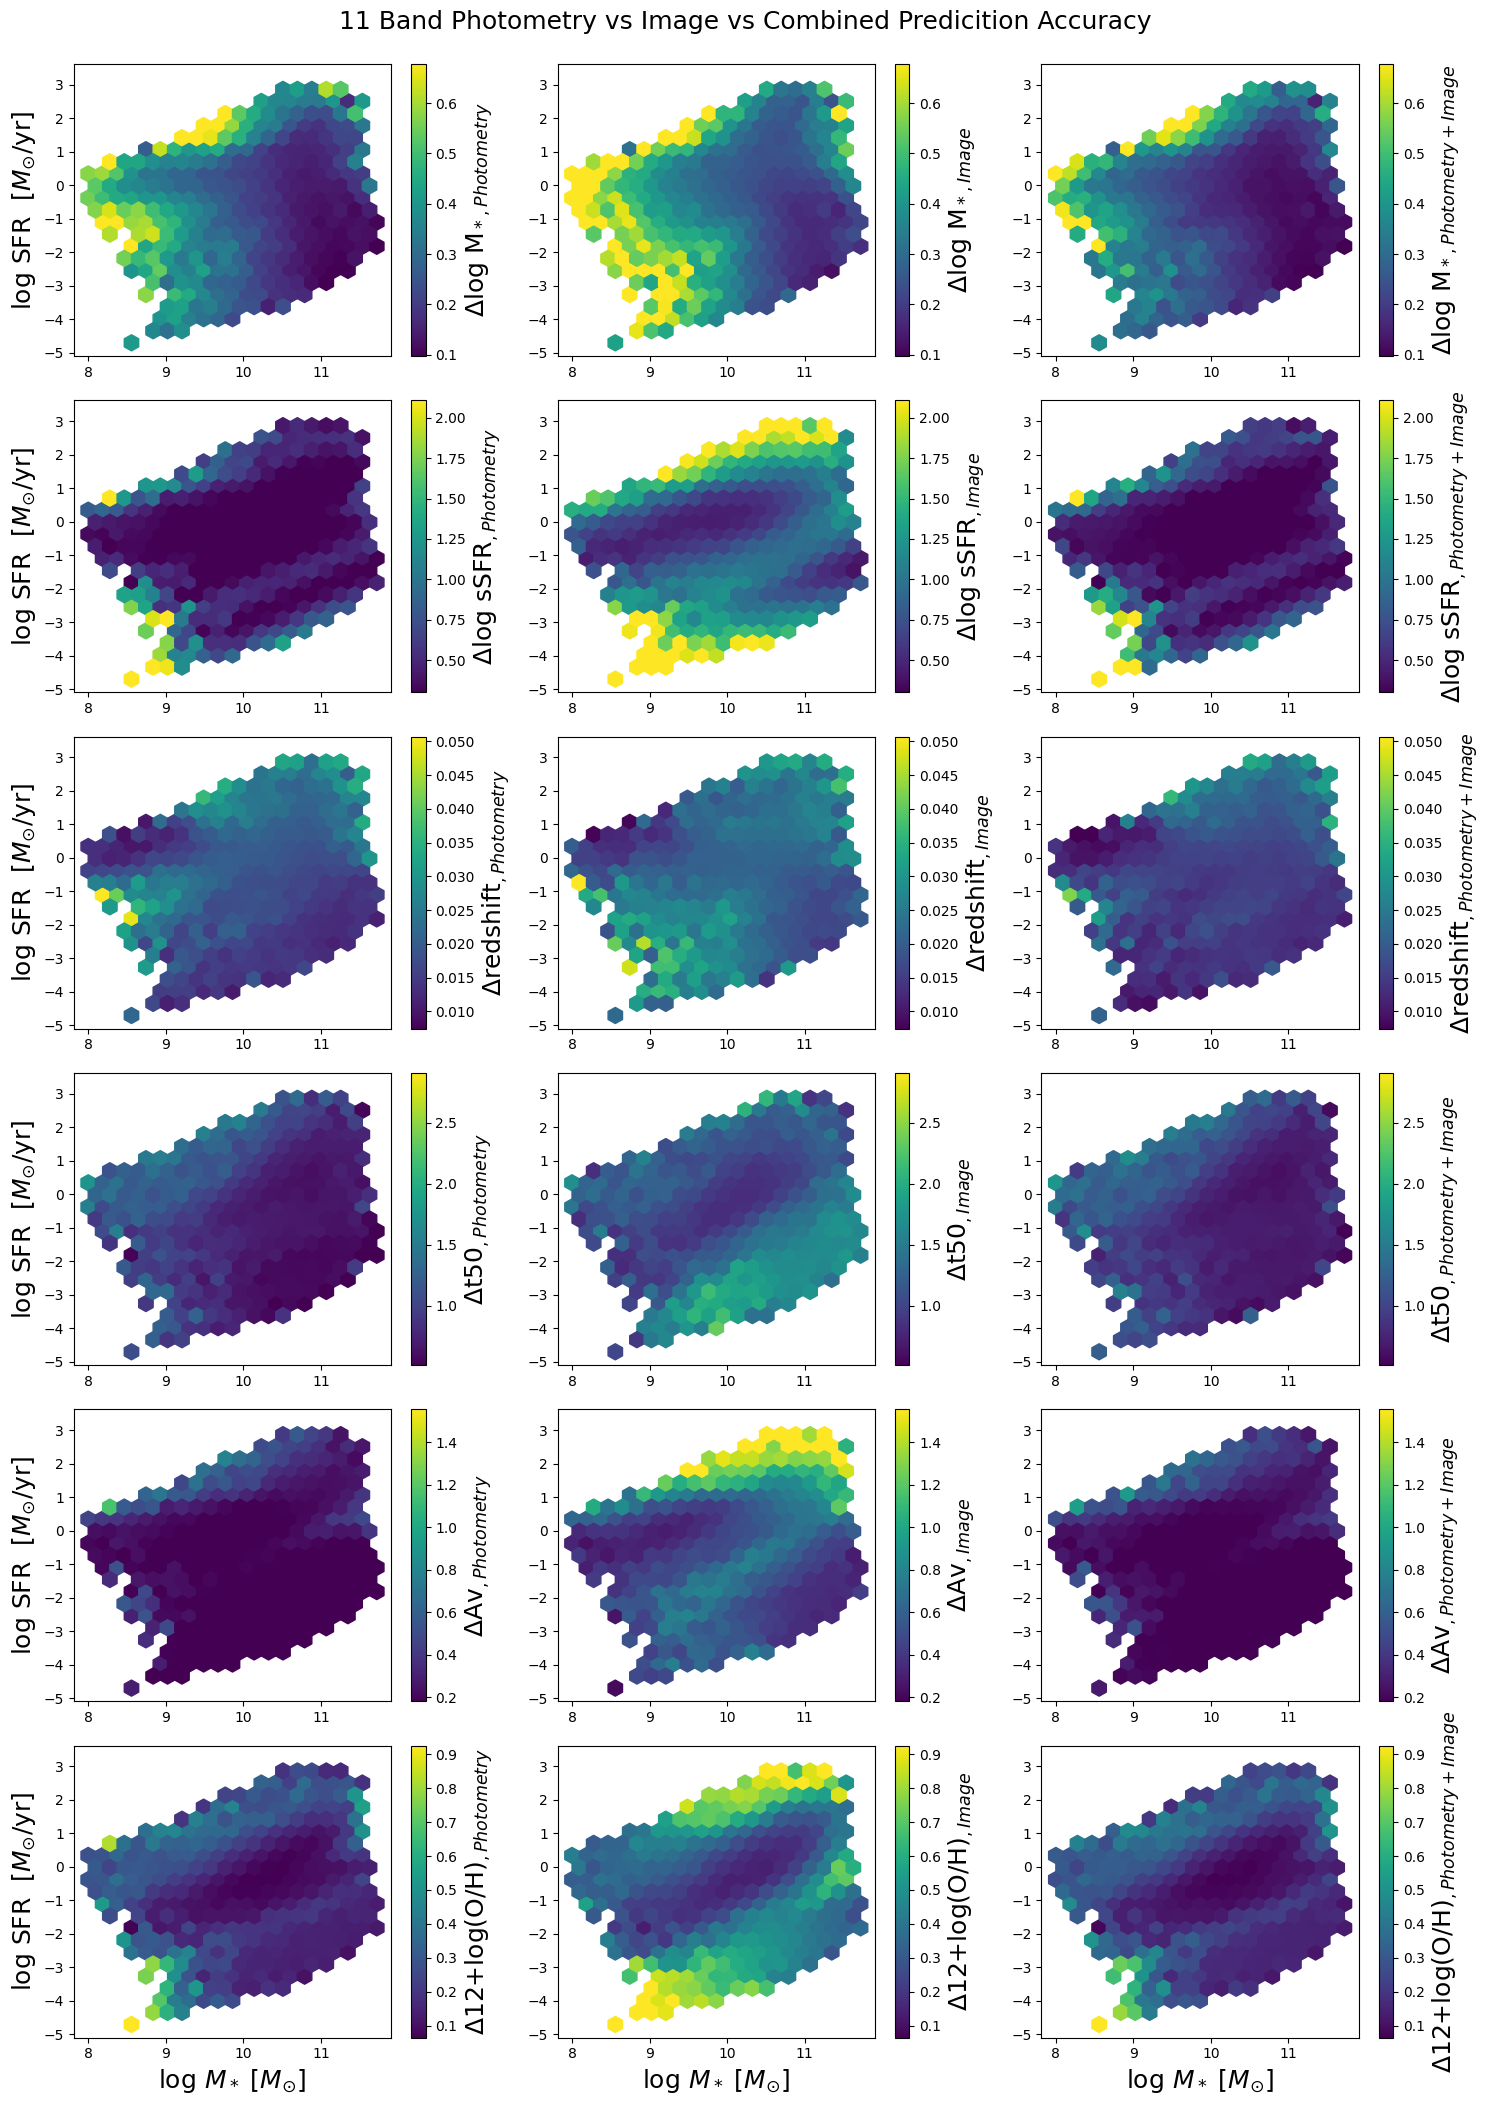

In [122]:
plt.subplots(figsize=(15,21),nrows=6, ncols=3)
plt.suptitle('11 Band Photometry vs Image vs Combined Predicition Accuracy',fontsize=18, y=1)
for qty in range(6):
    c_lower_bound = np.percentile(allimerr[:,qty],2)
    c_upper_bound = np.percentile(allimerr[:,qty],98)
    plt.subplot(6,3,qty*3+1)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_11_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$ [$M_{\odot}$]',fontsize=18) 
    plt.ylabel('log SFR  [$M_{\odot}$/yr]',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Photometry}$',fontsize=18)
    
    plt.subplot(6,3,qty*3+2)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allimerr[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$ [$M_{\odot}$]',fontsize=18)  
    # plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Image}$',fontsize=18)
    plt.tight_layout()

    plt.subplot(6,3,qty*3+3)
    plt.hexbin(mvals,sfrvals,gridsize=20,mincnt=2, C = allsederr_combined_11_bands[:,qty], vmin=c_lower_bound, vmax=c_upper_bound, cmap='viridis')
    if qty ==5:
        plt.xlabel('log $M_*$ [$M_{\odot}$]',fontsize=18) 
    # plt.ylabel('log SFR',fontsize=18)
    clbr = plt.colorbar()
    templim = plt.gci().get_clim()
    clbr.set_label('$\Delta$'+labels[qty]+'$_{,Photometry+Image}$',fontsize=18)

plt.savefig('/home/juanpabloalfonzo/Documents/ViT Morph Fitting/Plots/11_bands_SED_vs_image_vs_combined.pdf', dpi=300, bbox_inches='tight')


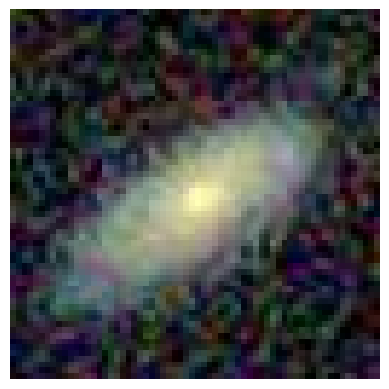

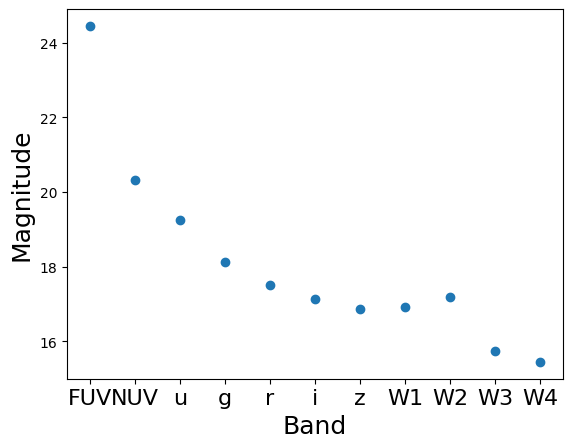

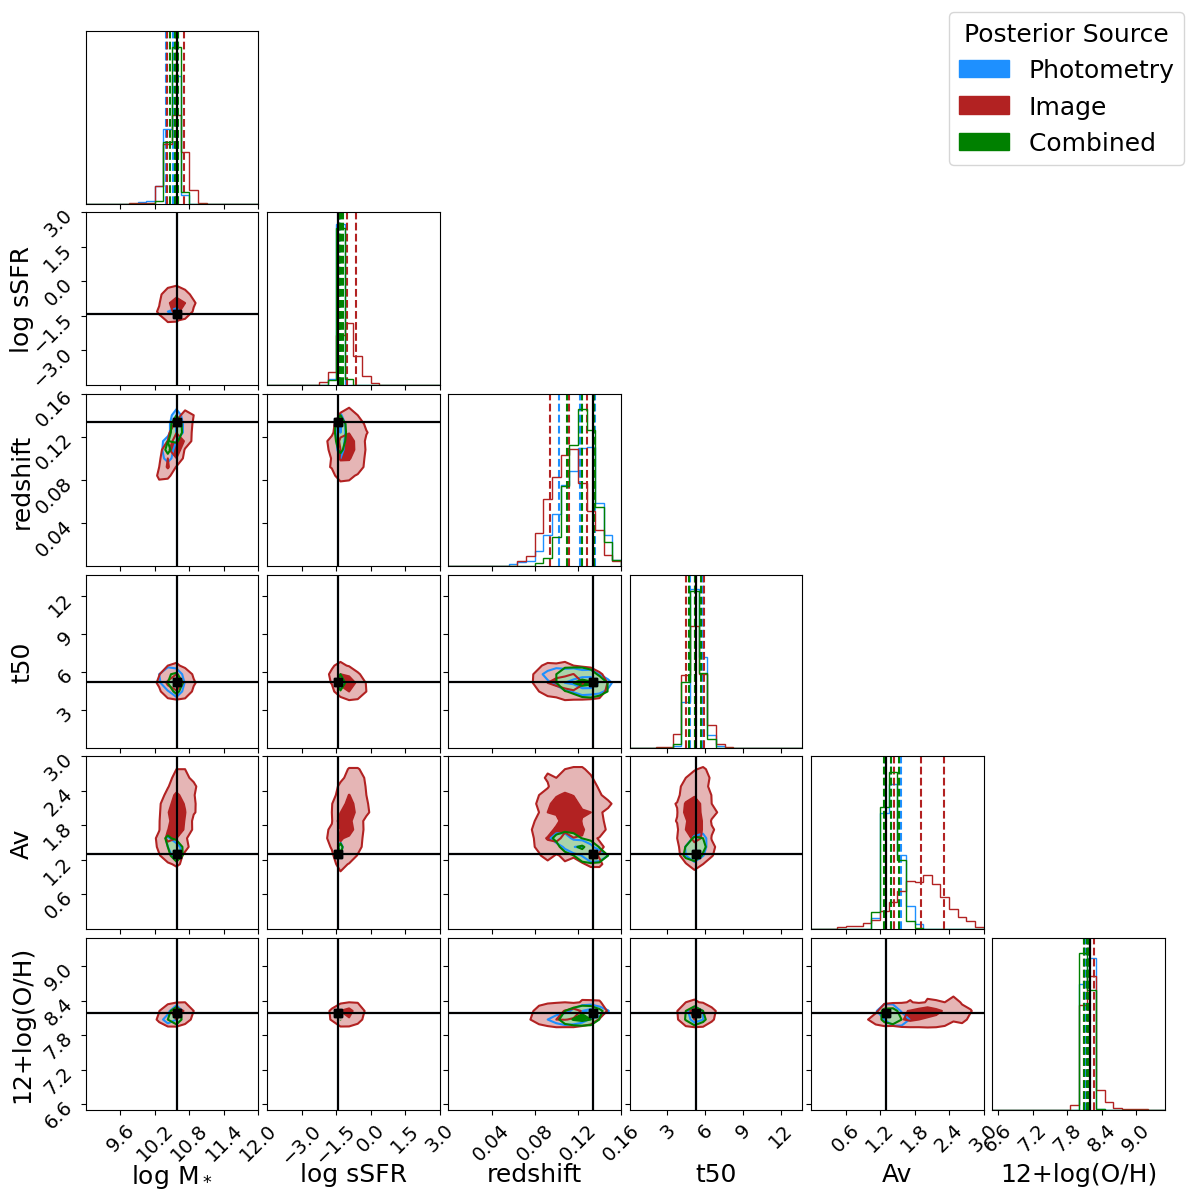

In [125]:
clrs = plt.cm.Spectral(np.linspace(0,1,10))
ranges = [(9,12),(-4.5,3),(0,0.16),(0,13.7),(0,3),(6.5,9.5)]
labels = ['log M$_*$', 'log sSFR','redshift','t50','Av','12+log(O/H)']


np.random.seed(256)
random_gal = np.random.randint(train_index, len(gswlc_data), size=(1))
random_gal = np.array(random_gal[0],dtype=int)

gid = random_gal
xobs_sed = eleven_bands_SED[gid,:]
xobs_im = gswlc_embeds[gid,:]
x_truth = theta[gid,:]

posterior_samples_sed = posterior_ensemble_sed.sample((1000,), torch.Tensor(xobs_sed).to(device), show_progress_bars = False)
posterior_samples_sed = posterior_samples_sed.cpu().numpy()


posterior_samples_im = posterior_ensemble_im.sample((1000,), torch.Tensor(xobs_im).to(device), show_progress_bars = False)
posterior_samples_im = posterior_samples_im.cpu().numpy()

posterior_samples_combined = posterior_ensemble_combined_11_bands.sample((1000,), torch.Tensor(np.hstack((xobs_im,xobs_sed))).to(device), show_progress_bars = False)
posterior_samples_combined = posterior_samples_combined.cpu().numpy()

plt.imshow(Image.open(io.BytesIO(gswlc_images[gid])))
plt.axis('off')
plt.figure()
plt.scatter(np.arange(11),xobs_sed)
plt.xticks(np.arange(0,11),['FUV','NUV','u','g','r','i','z','W1', 'W2', 'W3','W4'],fontsize=16)
plt.xlabel('Band',fontsize=18)
plt.ylabel('Magnitude',fontsize=18)
fig = corner.corner(posterior_samples_sed, truths=x_truth,color='dodgerblue',range=ranges,labels=labels, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig = corner.corner(posterior_samples_im, truths=x_truth, truth_color='k',color='firebrick',range=ranges,labels=labels,fig=fig, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
fig = corner.corner(posterior_samples_combined, truths=x_truth, truth_color='k',color='green',range=ranges,labels=labels,fig=fig, plot_datapoints=False, fill_contours=True,quantiles=(0.16, 0.5, 0.84),levels=[1 - np.exp(-(1/1)**2/2),1 - np.exp(-(2/1)**2/2)])
import matplotlib.patches as mpatches
sed_legend_patch = mpatches.Patch(color='dodgerblue', label='Photometry')
image_legend_patch = mpatches.Patch(color='firebrick', label='Image')
combined_legend_patch = mpatches.Patch(color='green', label='Combined ')
fig.legend(handles=[sed_legend_patch, image_legend_patch, combined_legend_patch],
           loc='upper right', # Try different locations e.g. 'center left', 'lower center'
           fontsize='18', # Or a specific number like 10 or 12
           title='Posterior Source', # Optional title for the legend
           frameon=True,
           title_fontsize ='18') # Optional: draw a frame around the legend
fig.set_size_inches(12,12)
#adjust font size
for label in fig.get_axes():
    label.xaxis.label.set_size(18)
    label.yaxis.label.set_size(18)
    for tick in label.get_xticklabels():
        tick.set_fontsize(14)
    for tick in label.get_yticklabels():
        tick.set_fontsize(14)
plt.show()